# 第2回 演習: LoRA で回答形式を学習し、学習前後を比較する

架空の講座 FAQ を題材に、小さな指示チューニング済みモデルを LoRA で短時間学習し、学習の前後で **何が変わり、何が変わらないか** を比べます。評価は **形式遵守率**（`answer` と `needs_review` の JSON を守れたか）と **内容正解率** に分けます。

**この演習で確かめること**

1. プロンプトで形式を指示しても、小さなモデルは守れないことがある（セクション 3、学習前）。
2. LoRA で数分学習すると、形式はほぼ守れるようになる（セクション 5、学習後）。
3. 形式が整っても、FAQ に無いことを聞かれたときの判断（確認を求めるか、断定してしまうか）までは保証されない（セクション 5、6）。
4. 発展: 同じモデルを 4bit 量子化で読み込むと、学習しなくても出力が変わる（セクション 8）。

**進め方**

| セクション | 内容 | 所要時間の目安（T4） |
| --- | --- | --- |
| 0〜3 | 環境、設定、データ生成、モデル読み込み、学習前評価 | 約 5 分 |
| 4〜7 | 学習、学習後評価、知識質問、比較表と提出 | 約 10 分（学習 4〜5 分を含む） |
| 8（任意） | 4bit 量子化で読み込んで比べる | 約 2 分 |

授業前に 0〜3 を実行して環境が動くことを確かめておくと、当日の詰まりが減ります（任意）。Colab はセッションが切れると変数が消えるので、その場合は当日あらためて 0 から実行します。

**使うもの**: Google Colab（T4 GPU、無料枠）。モデルは `Qwen/Qwen3.5-0.8B`（Apache-2.0）。データはこのノートブックが生成する架空データで、実在の締切や URL は含みません。

**読み方**: 各セクションの説明に「やること」「見るところ」「うまくいかないとき」を書いています。セルは上から順に実行してください。途中のセルを飛ばすと、後のセルで変数が見つからないエラーになります。

版: 1.1（2026-10-18）

---

**Homework added to this notebook (run after section 8, or skip section 8)**

| Section | Homework level | What it does | Time (T4) |
| --- | --- | --- | --- |
| 9 | Basic | Retrains with one change each (`num_train_epochs=5`, `lora_r=4`) and compares against the section 4 run as the baseline | ~10 min |
| 10 | Advanced | Trains on the glossary data from `scripts/make_sft_dataset.py`, evaluates 45 questions, and compares with a glossary-search baseline | ~30–40 min |

Sections 0–8 are unchanged from the course notebook (v1.1), apart from recording the training time in section 4. Sections 9 and 10 reuse the same model, scoring and training code, so all numbers are comparable.

## 0. 環境の確認とライブラリの導入

**やること**: GPU が割り当てられているかを確認し、ライブラリを動作確認済みの版に固定して導入します。

**見るところ**

- 1 つ目のセルに `Tesla T4` と表示されること。
- 2 つ目のセルの最後に、版の一覧（`transformers: 5.18.0` など）が表示されること。導入は 1 分ほどかかります。

**うまくいかないとき**

- 「GPU が見つかりません」と出る: メニューの「ランタイム」→「ランタイムのタイプを変更」→「T4 GPU」を選び、セルを実行し直します。混雑で割り当てられないときは、時間をおいて試します。
- pip の赤い `ERROR: pip's dependency resolver ...`（`cudf` や `pyarrow` に関するもの）は、Colab に最初から入っている別のパッケージとの食い違いの警告です。この演習には影響しないので、そのまま進めます。

In [ ]:
import subprocess
try:
    gpu_info = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv"], capture_output=True, text=True).stdout
except FileNotFoundError:   # CPU ランタイムには nvidia-smi が無い
    gpu_info = ""
print(gpu_info or "GPU が見つかりません。ランタイム → ランタイムのタイプを変更 → T4 GPU を選んでください。")

name, memory.total [MiB]
Tesla T4, 15360 MiB



In [ ]:
# Colab の T4（Python 3.13、torch 2.11.0+cu130）で動作確認した版。torch は Colab 同梱のものをそのまま使う
PINS = {
    "transformers": "5.18.0",   # Qwen3.5 は transformers 5 系が必要
    "peft": "0.21.1",           # LoRA の実装
    "trl": "1.14.2",            # 学習ループ（SFTTrainer）
    "accelerate": "1.15.0",
    "datasets": "5.1.0",
}
spec = " ".join(f'"{k}=={v}"' for k, v in PINS.items())
%pip uninstall -y -q torchao   # Colab 同梱の torchao（0.10）は peft 0.21 と非互換で、学習時に ImportError になる。使わないので外す
%pip install -q {spec}

# cudf-cu13 と pyarrow の依存警告が ERROR 表示されるが、cudf は使わないので無視してよい
import transformers, peft, trl, accelerate, datasets, torch
print({m.__name__: m.__version__ for m in [transformers, peft, trl, accelerate, datasets, torch]})

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
{'transformers': '5.18.0', 'peft': '0.21.1', 'trl': '1.14.2', 'accelerate': '1.15.0', 'datasets': '5.1.0', 'torch': '2.11.0+cu130'}


## 1. 設定

**やること**: モデル名、学習のエポック数（データを何周するか）などを 1 つの辞書 `CONFIG` にまとめます。この辞書はセクション 7 の提出用ファイルにそのまま記録されるので、「どの条件で測ったか」が後から分かります。

- `revision` を固定しているのは、いつ実行しても同じ重みを使うためです。学習前後の比較や、他の人との比較で条件が揃います。
- `num_train_epochs: 20` は、学習データ（14 件）を 20 周する設定です。1 周が 2 ステップなので合計 40 ステップで、T4 で学習が 4〜5 分に収まります。
- `gen: {"do_sample": False}` は貪欲生成です。学習前後で生成条件を揃え、揺れの影響を除きます。

`USE_DRIVE` を `True` にすると Google Drive をマウントし、学習した adapter と結果ファイルを Drive にも保存します。セッションが切れても結果を残したいときに使います。1 回のセッションで完結させるなら `False` のままで構いません。

**見るところ**: 設定の JSON が表示されます。

In [ ]:
from pathlib import Path
import os, json, time

CONFIG = {
    "base_model": "Qwen/Qwen3.5-0.8B",   # 小さな指示チューニング済みモデル（Apache-2.0）。量子化なしで T4 に載る大きさ
    "revision": "2fc06364715b967f1860aea9cf38778875588b17",  # いつ実行しても同じ重みを使うために固定
    "seed": 42,
    "num_train_epochs": 20,  # 学習データ（14 件）を何周学習するか。1 周 2 ステップなので合計 40 ステップ（T4 で 4〜5 分）
    "warmup_steps": 6,
    "lr": 2e-4,
    "lora_r": 16,            # LoRA の行列の次元（小さいほど学習するパラメータが少ない）
    "lora_alpha": 32,
    "max_seq_len": 512,
    "max_new_tokens": 96,
    "gen": {"do_sample": False},   # 評価は貪欲生成で固定（前後比較の条件を揃える）
    "work_dir": "/content/qlora_lab",                          # 結果ファイルの保存先（左のファイル一覧から見られる）
    "drive_dir": "/content/drive/MyDrive/aie2026/qlora_lab",  # USE_DRIVE=True のときの保存先
}
WORK = Path(CONFIG["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)

USE_DRIVE = False  # True にすると Google Drive をマウントして adapter と出力を保存する
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    Path(CONFIG["drive_dir"]).mkdir(parents=True, exist_ok=True)
print(json.dumps(CONFIG, ensure_ascii=False, indent=2))

{
  "base_model": "Qwen/Qwen3.5-0.8B",
  "revision": "2fc06364715b967f1860aea9cf38778875588b17",
  "seed": 42,
  "num_train_epochs": 20,
  "warmup_steps": 6,
  "lr": 0.0002,
  "lora_r": 16,
  "lora_alpha": 32,
  "max_seq_len": 512,
  "max_new_tokens": 96,
  "gen": {
    "do_sample": false
  },
  "work_dir": "/content/qlora_lab",
  "drive_dir": "/content/drive/MyDrive/aie2026/qlora_lab"
}


## 2. 架空 FAQ と教師データの生成

**やること**: 5 項目の架空 FAQ から、学習用（train）、検証用（valid）、評価用（test）のデータを作ります。

モデルへの入力は「FAQ ＋ 質問」、望ましい出力は `{"answer": <文字列>, "needs_review": <真偽値>}` の JSON 1 行です。

- FAQ に根拠がある質問には、FAQ の文で答え、`needs_review: false` にする。
- FAQ に無い質問には、「この FAQ には記載がありません。運営に確認が必要です。」と答え、`needs_review: true` にする。

**データの分け方**

- 同じ FAQ 項目を聞く質問の言い換えを、**テンプレート単位**で train / valid / test に振り分けます。学習で見た文がそのまま test に出ないようにするためです。
- test は 21 問（根拠あり 15、根拠なし 6）です。件数を確保するため、test にだけ使う質問を別に用意しています。
- 正解（`needs_review` の値と、答えに含まれるべき語句）は `gold` に分けて持ち、モデルには渡しません。
- train は 14 件（根拠あり 10、根拠なし 4）、valid は 7 件です。FAQ が 5 項目しかないので学習データは少なく、同じ例を何回も学習することになります。何回学習するかは、データを複製して増やすのではなく、セクション 4 のエポック数（`num_train_epochs`）で決めます。データのファイルには実例だけを入れ、学習量は学習の設定で持つのが基本です。

**見るところ**: `train=14 valid=7 test=21 gold=21` と、学習例の 1 件（質問と、望ましい出力）が表示されます。質問が train / valid / test のどれかで重複していると、ここでエラーになります。

In [ ]:
FAQ = {
    "deadline": "課題の提出期限は 9 月 30 日 23:59（日本時間）です。",
    "destination": "提出先は学習ポータルの「課題」欄です。",
    "format": "提出形式は PDF 1 ファイルで、ファイル名は 学籍番号_課題番号.pdf です。",
    "office_hours": "質問は毎週火曜 17:00〜18:00 のオフィスアワーで受け付けます。",
    "late": "期限後の提出は、期限から 48 時間以内なら減点のうえ受け付けます。",
}
FAQ_TEXT = "\n".join(f"- {v}" for v in FAQ.values())

# 根拠あり: (FAQ キー, 質問テンプレート群, 正解の answer に含まれるべき語)
GROUNDED = {
    "deadline": (["課題の提出期限はいつですか", "いつまでに出せばいいですか", "締切を教えてください", "提出の期限は？"], ["9 月 30 日", "23:59"]),
    "destination": (["提出先はどこですか", "どこにアップロードしますか", "課題はどこから出しますか", "提出場所は？"], ["学習ポータル", "課題"]),
    "format": (["提出形式を教えてください", "ファイル名の決まりはありますか", "何のファイル形式で出しますか", "PDF 以外でも出せますか"], ["PDF"]),
    "office_hours": (["質問はいつできますか", "オフィスアワーはいつですか", "先生に質問する時間はありますか", "相談できる時間帯は？"], ["火曜", "17:00"]),
    "late": (["遅れて出したらどうなりますか", "期限を過ぎた場合は受け付けますか", "遅延提出のルールは？", "締切後の扱いを教えてください"], ["48 時間", "減点"]),
}
# 根拠なし: FAQ に無いので needs_review=true が正解
UNGROUNDED = [
    "再提出はできますか", "欠席した回の扱いを教えてください", "他の受講者の点数は見られますか",
    "成績はいつ出ますか", "提出期限は延長できますか", "グループでの提出は可能ですか",
    "課題の配点はどうなっていますか", "講義の録画は公開されますか",
]

# test 専用の追加質問（train / valid には入れない）
TEST_EXTRA_GROUNDED = {
    "deadline": ["提出期限の日付と時刻を教えてください", "課題の締切は何月何日の何時ですか"],
    "destination": ["課題の提出はどこで行いますか", "提出物を出す先を教えてください"],
    "format": ["提出するファイルの形式は何ですか", "提出ファイルは何形式で、いくつ出しますか"],
    "office_hours": ["オフィスアワーの曜日と時間を教えてください", "質問を受け付けてもらえるのは何曜日の何時からですか"],
    "late": ["提出が締切に間に合わなかったらどうなりますか", "期限後に提出した課題は受理されますか"],
}
TEST_EXTRA_UNGROUNDED = [
    "課題の文字数に制限はありますか", "提出した課題へのフィードバックはもらえますか",
    "参考文献の書き方に指定はありますか", "オフィスアワーは事前予約が必要ですか",
]
UNGROUNDED_ANSWER = "この FAQ には記載がありません。運営に確認が必要です。"

def make_example(question: str, answer: str, needs_review: bool) -> dict:
    target = json.dumps({"answer": answer, "needs_review": needs_review}, ensure_ascii=False)
    return {"question": question, "faq": FAQ_TEXT, "target": target, "needs_review": needs_review}

def split_templates(templates):
    # テンプレートの先頭 2 つを train、3 つ目を valid、4 つ目を test に固定（言い換えを跨がせない）
    return templates[:2], templates[2:3], templates[3:4]

train, valid, test, gold = [], [], [], {}
for key, (templates, must_include) in GROUNDED.items():
    tr, va, te = split_templates(templates)
    for q in tr: train.append(make_example(q, FAQ[key], False))
    for q in va: valid.append(make_example(q, FAQ[key], False))
    for q in te + TEST_EXTRA_GROUNDED[key]:
        test.append(make_example(q, FAQ[key], False)); gold[q] = {"needs_review": False, "must_include": must_include}
for i, q in enumerate(UNGROUNDED):
    ex = make_example(q, UNGROUNDED_ANSWER, True)
    bucket = [train, train, valid, test][i % 4]   # 根拠なしの質問は 4 問ごとに train 2 / valid 1 / test 1 に振る
    bucket.append(ex)
    if bucket is test: gold[q] = {"needs_review": True, "must_include": ["確認"]}
for q in TEST_EXTRA_UNGROUNDED:
    test.append(make_example(q, UNGROUNDED_ANSWER, True)); gold[q] = {"needs_review": True, "must_include": ["確認"]}

# train は 14 件（根拠あり 10、根拠なし 4）。同じ例を何回学習するかは、データを複製せず、セクション 4 の num_train_epochs で決める
all_questions = [r["question"] for r in train + valid + test]
assert len(set(all_questions)) == len(all_questions), "質問が train / valid / test のどこかで重複しています。テンプレートを見直してください"
print(f"train={len(train)} valid={len(valid)} test={len(test)} gold={len(gold)}")
print("学習例の 1 件 | 質問:", train[0]["question"], "| 望ましい出力:", train[0]["target"])
_ = (WORK / "train.jsonl").write_text("\n".join(json.dumps(r, ensure_ascii=False) for r in train), encoding="utf-8")
_ = (WORK / "test.jsonl").write_text("\n".join(json.dumps(r, ensure_ascii=False) for r in test), encoding="utf-8")
_ = (WORK / "gold.json").write_text(json.dumps(gold, ensure_ascii=False, indent=2), encoding="utf-8")

train=14 valid=7 test=21 gold=21
学習例の 1 件 | 質問: 課題の提出期限はいつですか | 望ましい出力: {"answer": "課題の提出期限は 9 月 30 日 23:59（日本時間）です。", "needs_review": false}


## 3. モデルの読み込みと学習前評価

**やること**: 基盤モデルを量子化なし（32bit）で読み込み、test の 21 問に答えさせて採点します。

プロンプト（`SYSTEM`）には「必ず JSON 1 行で、`answer` と `needs_review` を返す」と書いてあります。つまり **形式は指示済み** です。このモデルがその指示を守れるかどうかが、学習前の確認点です。

**採点のしかた**（セクション 5 でも同じ関数を使います）

- **形式**: JSON として読め、キーが `answer` と `needs_review` のちょうど 2 つで、型が文字列と真偽値であること。
- **内容**: `needs_review` が正解と一致し、かつ正解の語句（例: 「9 月 30 日」と「23:59」）が `answer` に含まれること。

内容の判定には `needs_review` の一致が必要です。そのため、キーが欠けている出力は、文面が正しくても内容は × になります。文面そのものは、表で自分の目で確かめてください。

`Qwen/Qwen3.5-0.8B` は画像も扱えるモデルですが、`AutoModelForCausalLM` で読み込むとテキスト部分だけが使われます。

**見るところ**

- 1 つ目のセル: `重みのメモリ(GB): 3.01` のように表示されます。モデルのダウンロード（約 1.75GB）に 1 分ほどかかります。
- 2 つ目のセル: 1 行の要約（`format_rate`、`content_rate` など）と、21 問の出力の表。評価には 1 分前後かかります。学習前は、多くの出力で `needs_review` が欠けているはずです。

**出ても問題ない警告**

- `You are sending unauthenticated requests to the HF Hub`: Hugging Face にログインせずにモデルを取りに行っている、という案内です。公開モデルはログインしなくてもダウンロードできます。ログインが要るのは次の場合で、モデルの大きさでは決まりません。
  - 利用規約への同意が必要なモデル（gated model。Llama や Gemma など）や、非公開のリポジトリを使うとき。
  - 自分のモデルやデータを Hub にアップロードするとき。
  - 短時間に大量のリクエストを送り、回数の上限に当たるとき。上限はログインしていないと IP アドレスごとに 5 分あたり 3,000 回のファイル取得（2025 年 9 月時点の公表値。[Hub の rate limits](https://huggingface.co/docs/hub/rate-limits)）で、ログインすると上がります。
  
  このノートブックのモデルは公開されていて同意も不要です。読み込みで送るリクエストは多くても数十回なので、上限には届きません。もし上限に当たって `429 Too Many Requests` が出ても、ライブラリが待ち時間を読み取って自動で再試行します。ログインが必要になったときは、Colab の左側の鍵アイコン（シークレット）に Hugging Face のトークンを `HF_TOKEN` という名前で登録し、このノートブックからのアクセスを許可すると、自動で使われます。
- `... is falling back to its reference PyTorch implementation ...`: このモデルの一部の層（線形注意）に対する高速な実装が入っていないので、遅いが正しい実装で動くという案内です。4 行ほど出ます。

**ここで読んでおくこと**: 表を見て、「どのキーが欠けているか」「文面は FAQ と合っているか」を確認します。この表はセクション 5 で学習後の出力と並べて見ます。出力の原文は `/content/qlora_lab/eval_before.json` にも保存されています（左のファイル一覧から開けます）。

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
tok = AutoTokenizer.from_pretrained(CONFIG["base_model"], revision=CONFIG["revision"])
if tok.pad_token is None: tok.pad_token = tok.eos_token
# 量子化なし。重みは 32bit のまま保持する（dtype を省くと配布時の精度で読み込まれるので明示する）
model = AutoModelForCausalLM.from_pretrained(CONFIG["base_model"], revision=CONFIG["revision"], dtype=torch.float32).to(DEVICE)
model.config.use_cache = True
BASE_MEMORY_GB = round(model.get_memory_footprint() / 1e9, 2)
print("loaded:", CONFIG["base_model"], "| device:", DEVICE, "| 重みのメモリ(GB):", BASE_MEMORY_GB)

# 形式はプロンプトで指示している。モデルがこれを守れるかが学習前の確認点
SYSTEM = "あなたは講座 FAQ の回答係です。与えられた FAQ だけを根拠に、必ず JSON 1 行で答えてください。形式: {\"answer\": 文字列, \"needs_review\": 真偽値}。FAQ に記載が無いことは answer に『確認が必要』と書き、needs_review を true にします。"

def build_messages(example):
    user = f"FAQ:\n{example['faq']}\n\n質問: {example['question']}"
    return [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user}]

def generate(model, example):
    # enable_thinking=False: 思考ブロックを空にして回答だけを生成させる（モデルを替えても条件が揃うように明示）
    prompt = tok.apply_chat_template(build_messages(example), tokenize=False, add_generation_prompt=True, enable_thinking=False)
    inputs = tok(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=CONFIG["max_new_tokens"], pad_token_id=tok.pad_token_id, **CONFIG["gen"])
    return tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 12.8MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/7.75k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/50.9k [00:00<?, ?B/s]

model.safetensors-00001-of-00001.safeten(…): reconstructing file:   0%|          |  0.00B / 1.75GB            

model.safetensors-00001-of-00001.safeten(…): downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

loaded: Qwen/Qwen3.5-0.8B | device: cuda | 重みのメモリ(GB): 3.01


In [ ]:
import re
import pandas as pd
pd.set_option("display.max_colwidth", None)   # 出力の原文を省略せずに表示する

def check_format(text: str):
    '''JSON として読め、必須キーと型が合うか。失敗理由も返す'''
    try:
        obj = json.loads(text)
    except Exception as e:
        return False, f"json_error: {type(e).__name__}", None
    if not isinstance(obj, dict): return False, "not_object", None
    if set(obj) - {"answer", "needs_review"}: return False, "extra_keys", obj
    if "answer" not in obj or "needs_review" not in obj: return False, "missing_key", obj
    if not isinstance(obj["answer"], str) or not isinstance(obj["needs_review"], bool): return False, "wrong_type", obj
    return True, "", obj

def check_content(obj, gold_entry):
    '''内容の合否: needs_review が正解と一致し、必須語句を answer に含む'''
    if obj is None: return False
    if obj.get("needs_review") != gold_entry["needs_review"]: return False
    return all(w in obj.get("answer", "") for w in gold_entry["must_include"])

def mark(ok: bool) -> str:
    return "○" if ok else "×"

def evaluate(model, label: str):
    '''test の 21 問を生成して採点し、要約と質問ごとの結果を返す。原文は eval_<label>.json に保存する'''
    rows = []
    t0 = time.time()
    for ex in test:
        raw = generate(model, ex)
        ok_fmt, reason, obj = check_format(raw)
        # 形式が壊れていても JSON らしい部分が読めるなら、内容だけは別に採点する
        loose = obj
        if not ok_fmt:
            m = re.search(r"\{.*\}", raw, re.S)
            try: loose = json.loads(m.group(0)) if m else None
            except Exception: loose = None
        ok_content = check_content(loose if isinstance(loose, dict) else None, gold[ex["question"]])
        rows.append({"question": ex["question"], "raw": raw, "format_ok": ok_fmt, "format_reason": reason,
                     "content_ok": ok_content, "both_ok": ok_fmt and ok_content, "gold_needs_review": gold[ex["question"]]["needs_review"]})
    n = len(rows)
    summary = {"label": label, "n": n,
               "format_rate": sum(r["format_ok"] for r in rows)/n,
               "content_rate": sum(r["content_ok"] for r in rows)/n,
               "both_rate": sum(r["both_ok"] for r in rows)/n,
               "seconds": round(time.time()-t0, 1)}
    (WORK / f"eval_{label}.json").write_text(json.dumps({"summary": summary, "rows": rows}, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(summary, ensure_ascii=False))
    return summary, rows

before_summary, before_rows = evaluate(model, "before")
# 質問ごとの出力。「正解の needs_review」と見比べ、どのキーが欠けているか、文面は FAQ と合っているかを読む
display(pd.DataFrame([{"質問": r["question"], "正解の needs_review": r["gold_needs_review"], "学習前の出力": r["raw"],
                       "形式": mark(r["format_ok"]), "形式の失敗理由": r["format_reason"], "内容": mark(r["content_ok"])} for r in before_rows]))

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


{"label": "before", "n": 21, "format_rate": 0.09523809523809523, "content_rate": 0.0, "both_rate": 0.0, "seconds": 39.9}


,質問,正解の needs_review,学習前の出力,形式,形式の失敗理由,内容
0,提出の期限は？,False,"{""answer"": ""9 月 30 日 23:59""}",×,missing_key,×
1,提出期限の日付と時刻を教えてください,False,"{""answer"": ""9 月 30 日 23:59""}",×,missing_key,×
2,課題の締切は何月何日の何時ですか,False,"{""answer"": ""9 月 30 日 23:59""}",×,missing_key,×
3,提出場所は？,False,"{""answer"": ""学習ポータルの「課題」欄""}",×,missing_key,×
4,課題の提出はどこで行いますか,False,"{""answer"": ""学習ポータルの「課題」欄で提出先を指定し、PDF 1 ファイルで提出します。提出時間は毎週火曜 17:00〜18:00 のオフィスアワーで行います。""}",×,missing_key,×
5,提出物を出す先を教えてください,False,"{""answer"": ""学習ポータルの「課題」欄""}",×,missing_key,×
6,PDF 以外でも出せますか,False,"{""answer"": ""確認が必要""}",×,missing_key,×
7,提出するファイルの形式は何ですか,False,"{""answer"": ""PDF 1 ファイルで、ファイル名は 学籍番号_課題番号.pdf です""}",×,missing_key,×
8,提出ファイルは何形式で、いくつ出しますか,False,"{""answer"": ""PDF 1 ファイルで、1 出します""}",×,missing_key,×
9,相談できる時間帯は？,False,"{""answer"": ""火曜 17:00〜18:00 のオフィスアワー""}",×,missing_key,×


## 4. LoRA 学習（T4 で 4〜5 分）

### LoRA と QLoRA の違い

- **LoRA**: 基盤モデルの重みは固定し、一部の層に追加した小さな行列（adapter）だけを学習します。
- **QLoRA**: 基盤モデルの重みを 4bit に量子化して保持し、その上で同じように adapter だけを学習します。adapter 自体は量子化しません。

QLoRA の効果は、基盤モデルの重みを保持するメモリが減ることです。16bit の約 4 分の 1 になるので、そのままでは GPU に載らない大きさのモデルでも学習できます（70 億パラメータなら 16bit で約 14GB、4bit で約 3.5GB）。

| 観点 | LoRA（量子化なし） | QLoRA（4bit） |
| --- | --- | --- |
| 重みのメモリ | 大きい | 小さい（16bit の約 1/4） |
| 基盤モデルの出力 | 元のまま | 量子化の誤差で変わることがある。影響の大きさはモデルによって違う |
| 学習の速さ | 基準 | 速くはならない。4bit の重みを計算のたびに戻すので、遅くなることが多い |
| 依存ライブラリ | peft | peft に加えて bitsandbytes（CUDA の GPU が前提） |

QLoRA を実装するときの注意:

- 読み込み時に `BitsAndBytesConfig(load_in_4bit=True, ...)` を渡し、LoRA を付ける前に `prepare_model_for_kbit_training(model)` を通します。
- 保持精度（4bit）と計算精度（`bnb_4bit_compute_dtype`。16bit など）は別の設定です。
- 学習前後の比較は、同じ量子化条件の基盤モデルで行います。学習前を量子化なし、学習後を 4bit で測ると、量子化の影響と学習の影響が混ざります。
- adapter は学習時の基盤モデルに合わせて作られます。配布や再利用のときは、基盤モデルの ID・revision と量子化設定を一緒に記録します。
- 4bit での学習が勧められないモデルもあります。Qwen3.5 は量子化の誤差が通常より大きいとして、4bit 学習を勧めていない[学習ライブラリのガイド](https://unsloth.ai/docs/models/qwen3.5/fine-tune)があります。

この演習のモデルは量子化なしでも T4 に載るので、LoRA で学習します。モデルが GPU に載るなら LoRA、載らないなら QLoRA かより小さいモデル、という順で考えます。4bit で読み込んだ場合のメモリと出力の違いは、セクション 8（発展）で確かめられます。

### 学習の実行

**やること**: train の 14 件を chat 形式（system / user / assistant）に直し、LoRA を付けて 20 エポック（40 ステップ）学習します。学習した adapter は `adapter/` に保存します。

- `target_modules` は LoRA を差し込む層です。注意機構の射影（`q_proj` など）と MLP の射影（`gate_proj` など）を指定しています。このモデルは 24 層のうち 18 層が線形注意で、`q_proj` などを持つのは残りの 6 層だけです。MLP は全層にあります。
- バッチ 4 × 勾配累積 2 = 1 ステップ 8 件。train は 14 件なので 1 エポックは 2 ステップ（8 件と 6 件）で、20 エポックで 40 ステップです。各例をちょうど 20 回学習します。学習率の warmup と減衰（cosine）はこの 40 ステップに対して効きます。
- 学習後のモデルは変数 `tuned` に入ります。LoRA は基盤モデルの層に差し込まれるので、元の変数 `model` で生成しても adapter 込みの出力になります。学習前の出力が必要なときは、セクション 6 のように adapter を一時的に無効にします。

**見るところ**

- `trainable params: ... || all params: ... || trainable%: ...`: 学習するパラメータが全体の数 % だけであることが LoRA の特徴です。
- `Training Loss` の表（10 ステップごと）: 1.5 前後から始まり、40 ステップで 0.01〜0.02 まで下がります。下がらないまま終わった場合は、設定を変えていないか確かめてください。
- `学習時間: ... 秒 | ステップ数: 40 | エポック: 20.0`: T4 で 240〜290 秒です。ステップ数とエポックは、学習データ 14 件 × 20 周が上の計算どおりに実行されたことの確認です。

**出ても問題ない警告**: `The tokenizer has new PAD/BOS/EOS tokens that differ from the model config ...` は、終端トークンの設定を tokenizer に合わせたという案内です。

**うまくいかないとき**: 学習が途中で止まった、または学習できなかった場合は、下の 4b を読んでください。

In [ ]:
from peft import LoraConfig
from trl import SFTTrainer, SFTConfig
from datasets import Dataset

def to_chat(example):
    # 学習データは「入力（system + user）」と「望ましい出力（assistant）」の対。評価と同じ build_messages を使う
    return {"messages": build_messages(example) + [{"role": "assistant", "content": example["target"]}]}

train_ds = Dataset.from_list([to_chat(e) for e in train])
valid_ds = Dataset.from_list([to_chat(e) for e in valid])

model.config.use_cache = False
# Qwen3.5 は 24 層のうち 18 層が線形注意で、q/k/v/o_proj を持つのは残りの 6 層。gate/up/down_proj（MLP）は全層にある
lora = LoraConfig(r=CONFIG["lora_r"], lora_alpha=CONFIG["lora_alpha"], lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
                  target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
USE_AMP = False  # 通常は変えない。True にすると計算だけ 16bit の混合精度になる（CUDA のみ。重みは 32bit のまま）。速くなる一方、損失が nan になる場合がある
sft = SFTConfig(output_dir=str(WORK / "ckpt"), num_train_epochs=CONFIG["num_train_epochs"], per_device_train_batch_size=4, gradient_accumulation_steps=2,
                learning_rate=CONFIG["lr"], lr_scheduler_type="cosine", warmup_steps=CONFIG["warmup_steps"], logging_steps=10, save_steps=10, save_total_limit=2,
                fp16=USE_AMP, max_length=CONFIG["max_seq_len"], packing=False, report_to="none", seed=CONFIG["seed"])
trainer = SFTTrainer(model=model, args=sft, train_dataset=train_ds, eval_dataset=valid_ds, peft_config=lora, processing_class=tok)
trainer.model.print_trainable_parameters()   # LoRA で学習するパラメータの割合
t0 = time.time()
trainer.train()  # 途中で止まった場合の再開は 4b を参照
print(f"学習時間: {time.time()-t0:.0f} 秒 | ステップ数: {trainer.state.global_step} | エポック: {trainer.state.epoch:.1f}")
ADAPTER_DIR = WORK / "adapter"
trainer.model.save_pretrained(ADAPTER_DIR)
if USE_DRIVE:
    import shutil; shutil.copytree(ADAPTER_DIR, Path(CONFIG["drive_dir"]) / "adapter", dirs_exist_ok=True)
tuned = trainer.model
tuned.config.use_cache = True
_ = tuned.eval()  # 学習モードのままだと dropout が効き、評価の出力が揺れる（代入はモデル全体の表示を抑えるため）

Tokenizing train dataset:   0%|          | 0/14 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/14 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/14 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/14 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/7 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/7 [00:00<?, ? examples/s]

... (2 outputs left out)

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 248046}.


trainable params: 6,389,760 || all params: 758,782,784 || trainable%: 0.8421


Step,Training Loss
10,1.564916
20,0.084662
30,0.018158
40,0.013771


学習時間: 231 秒 | ステップ数: 40 | エポック: 20.0


### 4b. 学習が止まった・できなかった場合

**途中で止まった（ランタイムの切断など）**: チェックポイントは 10 ステップごとに `/content/qlora_lab/ckpt/` に保存されています。ファイルが残っていれば、セクション 0〜3 を実行し直してから、上の学習セルの `trainer.train()` を `trainer.train(resume_from_checkpoint=True)` に書き換えて実行すると、最後のチェックポイントから 40 ステップ（20 エポック）まで続きを学習します。ランタイムごと消えてファイルが無い場合は、学習をやり直すか、下の方法に切り替えます。

**学習できなかった（GPU が確保できない、時間内に終わらない）**: 講師が同じノートブックを T4 で実行した結果（学習後の出力とスコア）を使って、比較と考察を進めます。セクション 5 以降のセルは学習後のモデル `tuned` が無いと動かないので、講師の結果を見ながら説明を読んでください。提出するときは、セクション 7 の `executed_training_myself` を `False` にし、本人が実行できた範囲を明記します。

## 5. 学習後評価（学習前と同じ test・同じ生成設定）

**やること**: 学習後のモデル `tuned` で、学習前とまったく同じ 21 問・同じ生成設定で評価し、前後を並べます。変えたのは adapter の有無だけです。

**見るところ**

- 比較表: `format_rate`（形式遵守率）と `content_rate`（内容正解率）が学習前からどう変わったか。
- `退行`: 学習前は形式も内容も通っていたのに、学習後に落ちた質問です。空のリストが期待値です。
- 質問ごとの表: 残った失敗を読み、どの型かを見分けてください。
  - 根拠なしの質問（正解の `needs_review` が `True`）に、FAQ の別項目を当てはめて断定した。
  - 根拠ありの質問（正解が `False`）に、「記載がありません」と確認要求で逃げた。

学習後の回答は、教師データの文（FAQ の原文）をほぼそのまま返す形になります。形式と文面は揃いますが、「FAQ に根拠があるか」の判断まで学習できたとは限りません。

seed を固定しても、GPU 上の学習は完全には再現しません。形式遵守率と内容正解率の割合はほぼ同じでも、どの質問が残るかは実行ごとに変わることがあります。隣の人と「残った質問」が違っても異常ではないので、失敗の型で比べてください。

In [ ]:
after_summary, after_rows = evaluate(tuned, "after")
compare = pd.DataFrame([before_summary, after_summary]).set_index("label")[["n", "format_rate", "content_rate", "both_rate", "seconds"]]
display(compare)
# 学習前は形式も内容も通ったのに、学習後に落ちた質問（退行）
regressed = [b["question"] for b, a in zip(before_rows, after_rows) if b["both_ok"] and not a["both_ok"]]
print("退行:", regressed)

# 質問ごとの出力原文。形式（JSON・必須キー・型）と内容（needs_review の一致と必須語句）の判定を自分の目で確かめる
detail = pd.DataFrame([{"質問": b["question"], "正解の needs_review": b["gold_needs_review"],
                        "学習前の出力": b["raw"], "学習前 形式/内容": f"{mark(b['format_ok'])}/{mark(b['content_ok'])}",
                        "学習後の出力": a["raw"], "学習後 形式/内容": f"{mark(a['format_ok'])}/{mark(a['content_ok'])}"}
                       for b, a in zip(before_rows, after_rows)])
display(detail)

{"label": "after", "n": 21, "format_rate": 1.0, "content_rate": 0.9047619047619048, "both_rate": 0.9047619047619048, "seconds": 44.3}


,n,format_rate,content_rate,both_rate,seconds
label,,,,,
before,21,0.095238,0.000000,0.000000,39.9
after,21,1.000000,0.904762,0.904762,44.3


退行: []


,質問,正解の needs_review,学習前の出力,学習前 形式/内容,学習後の出力,学習後 形式/内容
0,提出の期限は？,False,"{""answer"": ""9 月 30 日 23:59""}",×/×,"{""answer"": ""課題の提出期限は 9 月 30 日 23:59（日本時間）です。"", ""needs_review"": false}",○/○
1,提出期限の日付と時刻を教えてください,False,"{""answer"": ""9 月 30 日 23:59""}",×/×,"{""answer"": ""課題の提出期限は 9 月 30 日 23:59（日本時間）です。"", ""needs_review"": false}",○/○
2,課題の締切は何月何日の何時ですか,False,"{""answer"": ""9 月 30 日 23:59""}",×/×,"{""answer"": ""課題の提出期限は 9 月 30 日 23:59（日本時間）です。"", ""needs_review"": false}",○/○
3,提出場所は？,False,"{""answer"": ""学習ポータルの「課題」欄""}",×/×,"{""answer"": ""提出先は学習ポータルの「課題」欄です。"", ""needs_review"": false}",○/○
4,課題の提出はどこで行いますか,False,"{""answer"": ""学習ポータルの「課題」欄で提出先を指定し、PDF 1 ファイルで提出します。提出時間は毎週火曜 17:00〜18:00 のオフィスアワーで行います。""}",×/×,"{""answer"": ""提出先は学習ポータルの「課題」欄です。"", ""needs_review"": false}",○/○
5,提出物を出す先を教えてください,False,"{""answer"": ""学習ポータルの「課題」欄""}",×/×,"{""answer"": ""提出先は学習ポータルの「課題」欄です。"", ""needs_review"": false}",○/○
6,PDF 以外でも出せますか,False,"{""answer"": ""確認が必要""}",×/×,"{""answer"": ""提出形式は PDF 1 ファイルで、ファイル名は 学籍番号_課題番号.pdf です。"", ""needs_review"": false}",○/○
7,提出するファイルの形式は何ですか,False,"{""answer"": ""PDF 1 ファイルで、ファイル名は 学籍番号_課題番号.pdf です""}",×/×,"{""answer"": ""提出形式は PDF 1 ファイルで、ファイル名は 学籍番号_課題番号.pdf です。"", ""needs_review"": false}",○/○
8,提出ファイルは何形式で、いくつ出しますか,False,"{""answer"": ""PDF 1 ファイルで、1 出します""}",×/×,"{""answer"": ""提出形式は PDF 1 ファイルで、ファイル名は 学籍番号_課題番号.pdf です。"", ""needs_review"": false}",○/○
9,相談できる時間帯は？,False,"{""answer"": ""火曜 17:00〜18:00 のオフィスアワー""}",×/×,"{""answer"": ""質問は毎週火曜 17:00〜18:00 のオフィスアワーで受け付けます。"", ""needs_review"": false}",○/○


## 6. 知識を問う質問（形式を学んでも知識は保証されない）

**やること**: 形式の実験とは別に、FAQ にも学習データにも無い事実を 3 問尋ねます（対照として FAQ にある質問を 1 問加えます）。望ましい応答は「確認が必要（`needs_review: true`）」です。

応答を 3 つに分類します。

| 分類 | 意味 |
| --- | --- |
| `format_error` | JSON の形式を守れていない（学習前に多い） |
| `needs_review` | 「記載がありません。確認が必要です」と返した（望ましい応答） |
| `asserted` | `needs_review: false` で言い切った。FAQ に無い質問に対してなら、根拠のない断定（創作）です |

**見るところ**: 学習前は形式違反になりやすく、学習後は「確認が必要」と「断定」の両方が出ることがあります。出力の原文も表に出すので、断定した場合に何を根拠にしたように見えるか（FAQ の別項目を流用しているか）を読んでください。「Fine-Tuning では知識は絶対に直らない」と先に結論にせず、今回のデータでの結果を報告します。

学習前の出力は、adapter を一時的に無効にして取っています（`tuned.disable_adapter()`）。

In [ ]:
KNOWLEDGE_QUESTIONS = [
    "この講座の最終課題の締切はいつですか",       # FAQ に無い（架空）
    "担当教員の名前は何ですか",                     # FAQ に無い
    "次回の講義のテーマは何ですか",                 # FAQ に無い
    "課題の提出期限はいつですか",                   # FAQ にある（対照）
]
def classify(raw):
    ok, _, obj = check_format(raw)
    if not ok or obj is None: return "format_error"
    return "needs_review" if obj["needs_review"] else "asserted"

knowledge_rows = []
for q in KNOWLEDGE_QUESTIONS:
    ex = make_example(q, "", True)
    # LoRA は基盤モデルの層に差し込まれるので、学習後は `model` で生成しても adapter 込みになる。学習前の出力は adapter を一時的に無効にして取る
    with tuned.disable_adapter():
        before_raw = generate(tuned, ex)
    after_raw = generate(tuned, ex)
    knowledge_rows.append({"質問": q, "FAQ にある": q in gold, "学習前の分類": classify(before_raw), "学習前の出力": before_raw,
                 "学習後の分類": classify(after_raw), "学習後の出力": after_raw})
display(pd.DataFrame(knowledge_rows))

,質問,FAQ にある,学習前の分類,学習前の出力,学習後の分類,学習後の出力
0,この講座の最終課題の締切はいつですか,False,format_error,"{""answer"": ""9 月 30 日 23:59""}",asserted,"{""answer"": ""課題の提出期限は 9 月 30 日 23:59（日本時間）です。"", ""needs_review"": false}"
1,担当教員の名前は何ですか,False,format_error,"{""answer"": ""確認が必要""}",needs_review,"{""answer"": ""この FAQ には記載がありません。運営に確認が必要です。"", ""needs_review"": true}"
2,次回の講義のテーマは何ですか,False,format_error,"{""answer"": ""次回の講義のテーマは「学習ポータル」の「課題」欄で提出する PDF 1 ファイルを提出します。""}",needs_review,"{""answer"": ""この FAQ には記載がありません。運営に確認が必要です。"", ""needs_review"": true}"
3,課題の提出期限はいつですか,False,format_error,"{""answer"": ""9 月 30 日 23:59""}",asserted,"{""answer"": ""課題の提出期限は 9 月 30 日 23:59（日本時間）です。"", ""needs_review"": false}"


## 7. 比較表と提出

**やること**: 設定、ライブラリの版、学習前後の要約、退行した質問を 1 つの `result.json` にまとめます。

**提出するもの**

- `result.json`、`eval_before.json`、`eval_after.json`（`/content/qlora_lab` にあります。左のファイル一覧で右クリック → ダウンロード。`USE_DRIVE = True` なら Drive にもコピーされます）
- セクション 5 の比較表と、残った失敗の説明（どの型の失敗か）
- セクション 6 の結果（確認要求に変わった応答、断定が残った応答）
- 本人が学習を実行した範囲。講師の結果を使った場合は `executed_training_myself` を `False` にしてください。

In [ ]:
result = {
    "config": {k: v for k, v in CONFIG.items() if k not in ("work_dir", "drive_dir")},
    "versions": {m.__name__: m.__version__ for m in [transformers, peft, trl, torch]},
    "method": "LoRA（量子化なし）",
    "before": before_summary, "after": after_summary,
    "regressed": regressed,
    "knowledge": knowledge_rows,
    "executed_training_myself": True,   # 講師の結果を使った場合は False にする
}
(WORK / "result.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps({k: v for k, v in result.items() if k != "knowledge"}, ensure_ascii=False, indent=2))
if USE_DRIVE:
    import shutil
    for name in ["result.json", "eval_before.json", "eval_after.json", "test.jsonl", "gold.json"]:
        shutil.copy(WORK / name, Path(CONFIG["drive_dir"]) / name)
    print("Drive に保存しました:", CONFIG["drive_dir"])

{
  "config": {
    "base_model": "Qwen/Qwen3.5-0.8B",
    "revision": "2fc06364715b967f1860aea9cf38778875588b17",
    "seed": 42,
    "num_train_epochs": 20,
    "warmup_steps": 6,
    "lr": 0.0002,
    "lora_r": 16,
    "lora_alpha": 32,
    "max_seq_len": 512,
    "max_new_tokens": 96,
    "gen": {
      "do_sample": false
    }
  },
  "versions": {
    "transformers": "5.18.0",
    "peft": "0.21.1",
    "trl": "1.14.2",
    "torch": "2.11.0+cu130"
  },
  "method": "LoRA（量子化なし）",
  "before": {
    "label": "before",
    "n": 21,
    "format_rate": 0.09523809523809523,
    "content_rate": 0.0,
    "both_rate": 0.0,
    "seconds": 39.9
  },
  "after": {
    "label": "after",
    "n": 21,
    "format_rate": 1.0,
    "content_rate": 0.9047619047619048,
    "both_rate": 0.9047619047619048,
    "seconds": 44.3
  },
  "regressed": [],
  "executed_training_myself": true
}


## 8. 発展: 4bit 量子化で読み込み、メモリと出力を比べる（任意）

**やること**: 同じモデルを 4bit（NF4）で読み込み、重みのメモリと、学習前の出力がどう変わるかを見ます。QLoRA は、この 4bit の基盤モデルに LoRA を付けて学習する方法です。ここでは学習はしません。

- bitsandbytes は CUDA の GPU が前提なので、GPU ランタイムでだけ動きます。導入に 1 分ほどかかります。
- 4bit の読み込みは `device_map="auto"` で GPU に配置します（bitsandbytes の読み込み方式に合わせています）。
- 4bit 側で学習まで試す場合は、`prepare_model_for_kbit_training(model_4bit)` を通してからセクション 4 と同じ手順で学習し、学習前後とも 4bit の基盤モデルで評価します。

**見るところ**

- 重みのメモリ: 32bit の約 3GB に対して 4bit は 1GB 未満になります。
- 比較表と質問ごとの表: 学習していないので、32bit の学習前（`before`）との差は量子化の影響です。良くなる方向に変わる質問もあれば、`needs_review` が `"false"`（文字列）になって型検査で落ちる、根拠なしの質問に「はい」「なし」と断定する、といった出力も見られます。方向が一定でないことを確かめてください。

In [ ]:
%pip install -q "bitsandbytes==0.50.*"
from transformers import BitsAndBytesConfig

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",   # 保持精度: 4bit（NF4）
                         bnb_4bit_compute_dtype=torch.float16,             # 計算精度: 16bit（T4 は bf16 に対応していない）
                         bnb_4bit_use_double_quant=True)
model_4bit = AutoModelForCausalLM.from_pretrained(CONFIG["base_model"], revision=CONFIG["revision"], quantization_config=bnb, device_map="auto")
print("重みのメモリ(GB) | 量子化なし（32bit）:", BASE_MEMORY_GB, "| 4bit:", round(model_4bit.get_memory_footprint() / 1e9, 2))

# 学習はしていないので、量子化なしの学習前（before）との差が量子化の影響
q_summary, q_rows = evaluate(model_4bit, "before_4bit")
display(pd.DataFrame([before_summary, q_summary]).set_index("label")[["n", "format_rate", "content_rate", "both_rate", "seconds"]])
display(pd.DataFrame([{"質問": r["question"], "正解の needs_review": r["gold_needs_review"], "4bit・学習前の出力": r["raw"],
                       "形式/内容": f"{mark(r['format_ok'])}/{mark(r['content_ok'])}", "形式の失敗理由": r["format_reason"]} for r in q_rows]))

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

重みのメモリ(GB) | 量子化なし（32bit）: 3.01 | 4bit: 0.76
{"label": "before_4bit", "n": 21, "format_rate": 0.6666666666666666, "content_rate": 0.3333333333333333, "both_rate": 0.3333333333333333, "seconds": 41.7}


,n,format_rate,content_rate,both_rate,seconds
label,,,,,
before,21,0.095238,0.000000,0.000000,39.9
before_4bit,21,0.666667,0.333333,0.333333,41.7


,質問,正解の needs_review,4bit・学習前の出力,形式/内容,形式の失敗理由
0,提出の期限は？,False,"{""answer"": ""9 月 30 日 23:59（日本時間）"", ""needs_review"": false}",○/○,
1,提出期限の日付と時刻を教えてください,False,"{""answer"": ""9 月 30 日 23:59"", ""needs_review"": false}",○/○,
2,課題の締切は何月何日の何時ですか,False,"{""answer"": ""9 月 30 日 23:59"", ""needs_review"": false}",○/○,
3,提出場所は？,False,"{""answer"": ""学習ポータルの「課題」欄"", ""needs_review"": false}",○/○,
4,課題の提出はどこで行いますか,False,"{""answer"": ""学習ポータルの「課題」欄で提出先を指定し、提出形式は PDF 1 ファイル（学籍番号_課題番号.pdf）で、提出時間は毎週火曜 17:00〜18:00 のオフィスアワーで受け付けます。""}",×/×,missing_key
5,提出物を出す先を教えてください,False,"{""answer"": ""学習ポータルの「課題」欄で提出先を指定してください。提出形式は PDF 1 ファイルで、ファイル名は 学籍番号_課題番号.pdf です。提出後、期限から 48 時間以内なら減点のうえ受け付けます。""}",×/×,missing_key
6,PDF 以外でも出せますか,False,"{""answer"": ""確認が必要""}",×/×,missing_key
7,提出するファイルの形式は何ですか,False,"{""answer"": ""PDF 1 ファイルで、ファイル名は 学籍番号_課題番号.pdf です""}",×/×,missing_key
8,提出ファイルは何形式で、いくつ出しますか,False,"{""answer"": ""PDF 1 ファイルで、1 出します"", ""needs_review"": false}",○/○,
9,相談できる時間帯は？,False,"{""answer"": ""17:00〜18:00"", ""needs_review"": false}",○/×,


## 9. Homework (Basic): change one hyperparameter, retrain, and compare

**What it does**: uses the section 4 run as the **baseline** (same `CONFIG`, so it is not retrained), then retrains with exactly one value changed per run, starting each time from a freshly loaded base model. That gives the same conditions as "Runtime → Restart session" without losing the exercise results.

**What to look at**: the comparison table (format_rate, content_rate, final loss, training time, trainable %), the loss curves, and which failure types remain in each run.

**Requires**: sections 0–7 have been run in this session (the baseline uses `trainer`, `tuned`, `after_rows` and `knowledge_rows`). Section 8 is optional; its 4-bit model is freed here.

**Output**: `result_baseline.json`, `result_epochs5.json`, `result_r4.json`, `loss_curves.png` and `answer_basic.md` in `/content/qlora_lab/`.

In [ ]:
import shutil

def to_drive(*names):
    if not USE_DRIVE: return
    for n in names:
        if (WORK / n).exists(): shutil.copy(WORK / n, Path(CONFIG["drive_dir"]) / n)

from peft import LoraConfig
from trl import SFTTrainer, SFTConfig
from datasets import Dataset

def to_chat(example):
    return {"messages": build_messages(example) + [{"role": "assistant", "content": example["target"]}]}

def train_lora(model, cfg, train_records, run_name, valid_records=None):
    """演習のセクション 4 と同じ学習。cfg の値だけを差し替えられるようにしている。学習時間と loss の推移を返す"""
    set_seed(cfg["seed"])                      # LoRA の初期値と学習順を揃える
    model.config.use_cache = False
    lora = LoraConfig(r=cfg["lora_r"], lora_alpha=cfg["lora_alpha"], lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
                      target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
    sft = SFTConfig(output_dir=str(WORK / f"ckpt_{run_name}"), num_train_epochs=cfg["num_train_epochs"],
                    per_device_train_batch_size=4, gradient_accumulation_steps=2,
                    learning_rate=cfg["lr"], lr_scheduler_type="cosine", warmup_steps=cfg["warmup_steps"],
                    logging_steps=cfg.get("logging_steps", 10), save_strategy="no",
                    fp16=False, max_length=cfg["max_seq_len"], packing=False, report_to="none", seed=cfg["seed"])
    trainer = SFTTrainer(model=model, args=sft, train_dataset=Dataset.from_list(train_records),
                         eval_dataset=Dataset.from_list(valid_records) if valid_records else None,
                         peft_config=lora, processing_class=tok)
    tuned = trainer.model
    trainable = sum(p.numel() for p in tuned.parameters() if p.requires_grad)
    total = sum(p.numel() for p in tuned.parameters())
    t0 = time.time()
    out = trainer.train()
    secs = round(time.time() - t0, 1)
    losses = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
    info = {"train_seconds": secs, "steps": trainer.state.global_step, "epochs": round(trainer.state.epoch, 2),
            "final_loss": losses[-1][1] if losses else None, "avg_train_loss": round(out.training_loss, 4),
            "loss_curve": losses, "trainable_params": trainable, "trainable_pct": round(100 * trainable / total, 3)}
    tuned.save_pretrained(WORK / f"adapter_{run_name}")
    tuned.config.use_cache = True
    tuned.eval()
    print(f"[{run_name}] 学習時間 {secs} 秒 | steps {info['steps']} | 最終 loss {info['final_loss']} | trainable {info['trainable_pct']}%")
    return tuned, info


TYPE_JA = {"形式の崩れ", "根拠なしに断定", "根拠ありで確認に逃げた", "語句不足"}
def failure_type(row):
    """Failure type, as in the exercise: format broken / asserted on ungrounded / dodged a grounded question / missing words"""
    if row["both_ok"]: return ""
    if not row["format_ok"]: return "形式の崩れ"
    obj = json.loads(row["raw"])
    if row["gold_needs_review"] and obj["needs_review"] is False: return "根拠なしに断定"
    if not row["gold_needs_review"] and obj["needs_review"] is True: return "根拠ありで確認に逃げた"
    return "語句不足"
def add_failure_types(rows):
    for r in rows: r["failure_type"] = failure_type(r)
    return rows
def knowledge_after(model):
    return [{"q": q, "cls": classify(raw), "raw": raw} for q in KNOWLEDGE_QUESTIONS for raw in [generate(model, make_example(q, "", True))]]
def pack_result(name, changed, cfg, info, after_summary_, after_rows_, k_after):
    add_failure_types(after_rows_)
    return {
        "run": name, "changed": changed,
        "config": {k: v for k, v in cfg.items() if k not in ("work_dir", "drive_dir")},
        "versions": {m.__name__: m.__version__ for m in [transformers, peft, trl, torch]},
        "method": "LoRA（量子化なし）", "train": info,
        "before": before_summary, "after": after_summary_,
        "regressed": [b["question"] for b, a in zip(before_rows, after_rows_) if b["both_ok"] and not a["both_ok"]],
        "remaining_failures": [{"question": a["question"], "type": a["failure_type"], "raw": a["raw"]} for a in after_rows_ if not a["both_ok"]],
        "knowledge": [{"質問": k["質問"], "FAQ にある": k["FAQ にある"], "学習前の分類": k["学習前の分類"], "学習前の出力": k["学習前の出力"],
                       "学習後の分類": a["cls"], "学習後の出力": a["raw"]} for k, a in zip(knowledge_rows, k_after)],
        "executed_training_myself": True,
    }

In [ ]:
EX_TRAIN_SECONDS = round(next(h["train_runtime"] for h in trainer.state.log_history if "train_runtime" in h), 1)
print(EX_TRAIN_SECONDS)

230.1


In [ ]:
import gc
from transformers import set_seed

def load_base():
    m = AutoModelForCausalLM.from_pretrained(CONFIG["base_model"], revision=CONFIG["revision"], dtype=torch.float32).to(DEVICE)
    m.config.use_cache = True
    return m

def cleanup():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

cleanup()
print("GPU memory in use (GB):", round(torch.cuda.memory_allocated() / 1e9, 2))

GPU memory in use (GB): 3.89


In [ ]:
# Baseline = the section 4 run (same CONFIG), so it is not retrained. Its numbers become result_baseline.json
# Safe to re-run: once the exercise model has been freed, this cell just reuses the saved file
import shutil, gc
from transformers import set_seed

# Helpers (in case section 3 came from an older copy of the notebook)
if "load_base" not in globals():
    def load_base():
        m = AutoModelForCausalLM.from_pretrained(CONFIG["base_model"], revision=CONFIG["revision"], dtype=torch.float32).to(DEVICE)
        m.config.use_cache = True
        return m
if "cleanup" not in globals():
    def cleanup():
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

if "trainer" not in globals() and (WORK / "result_baseline.json").exists():
    print("Baseline already saved; skipping:", json.loads((WORK / "result_baseline.json").read_text(encoding="utf-8"))["after"])
elif "trainer" not in globals():
    raise RuntimeError("No trained model from section 4 and no result_baseline.json: run sections 3-7 first")
else:
    if "EX_TRAIN_SECONDS" not in globals():
        EX_TRAIN_SECONDS = round(next((h["train_runtime"] for h in trainer.state.log_history if "train_runtime" in h), float("nan")), 1)
    _losses = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
    _avg = next((h["train_loss"] for h in trainer.state.log_history if "train_loss" in h), None)
    _trainable = sum(p.numel() for p in tuned.parameters() if p.requires_grad); _total = sum(p.numel() for p in tuned.parameters())
    baseline_info = {"train_seconds": EX_TRAIN_SECONDS, "steps": trainer.state.global_step, "epochs": round(trainer.state.epoch, 2),
                     "final_loss": _losses[-1][1] if _losses else None, "avg_train_loss": round(_avg, 4) if _avg is not None else None,
                     "loss_curve": _losses, "trainable_params": _trainable, "trainable_pct": round(100 * _trainable / _total, 3)}
    _k = [{"q": k["質問"], "cls": k["学習後の分類"], "raw": k["学習後の出力"]} for k in knowledge_rows]
    res = pack_result("baseline", {}, CONFIG, baseline_info, after_summary, after_rows, _k)
    (WORK / "result_baseline.json").write_text(json.dumps(res, ensure_ascii=False, indent=2), encoding="utf-8")
    shutil.copy(WORK / "eval_after.json", WORK / "eval_after_baseline.json")
    print(json.dumps({k: res[k] for k in ["run", "after", "regressed"]}, ensure_ascii=False))
    print("baseline train:", {k: v for k, v in baseline_info.items() if k != "loss_curve"})

# Free the exercise models (sections 3-8) so the next runs have the whole GPU
for _name in ["trainer", "tuned", "model", "model_4bit"]:
    if _name in globals(): del globals()[_name]
cleanup()
print("GPU memory in use (GB):", round(torch.cuda.memory_allocated() / 1e9, 2) if torch.cuda.is_available() else "-")

{"run": "baseline", "after": {"label": "after", "n": 21, "format_rate": 1.0, "content_rate": 0.9047619047619048, "both_rate": 0.9047619047619048, "seconds": 44.3}, "regressed": []}
baseline train: {'train_seconds': 230.1, 'steps': 40, 'epochs': 20.0, 'final_loss': 0.013771359622478486, 'avg_train_loss': 0.4204, 'trainable_params': 6389760, 'trainable_pct': 0.842}
GPU memory in use (GB): 3.05


In [ ]:
# Each run changes exactly ONE of lora_r / lr / num_train_epochs from CONFIG, and starts from a freshly loaded base model
# (equivalent to "Runtime → Restart session" — no adapter carries over)
RUNS = [
    {"name": "epochs5", "overrides": {"num_train_epochs": 5}},   # 1/4 of the training (40 → 10 steps)
    {"name": "r4",      "overrides": {"lora_r": 4}},             # smaller adapter (alpha stays 32, so alpha/r goes 2 → 8)
    # {"name": "lr2e-5", "overrides": {"lr": 2e-5}},            # optional: learning rate ÷10
]
for r in RUNS:
    assert len(r["overrides"]) == 1 and set(r["overrides"]) <= {"num_train_epochs", "lora_r", "lr"}, r

for run in RUNS:
    cfg = {**CONFIG, **run["overrides"]}
    m = load_base()
    tuned_run, info = train_lora(m, cfg, [to_chat(e) for e in train], run["name"], [to_chat(e) for e in valid])
    s_after, r_after = evaluate(tuned_run, f"after_{run['name']}")
    res = pack_result(run["name"], run["overrides"], cfg, info, s_after, r_after, knowledge_after(tuned_run))
    (WORK / f"result_{run['name']}.json").write_text(json.dumps(res, ensure_ascii=False, indent=2), encoding="utf-8")
    to_drive(f"result_{run['name']}.json", f"eval_after_{run['name']}.json")
    del tuned_run, m; cleanup()
print("done:", [r["name"] for r in RUNS])

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Tokenizing train dataset:   0%|          | 0/14 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/14 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/14 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/14 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/7 [00:00<?, ? examples/s]

... (14 outputs left out)

Dropping fully masked examples from eval dataset:   0%|          | 0/7 [00:00<?, ? examples/s]

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 248046}.


Step,Training Loss
10,1.539320
20,0.080322
30,0.016401
40,0.012686


[r4] 学習時間 232.2 秒 | steps 40 | 最終 loss 0.01268608272075653 | trainable 0.212%
{"label": "after_r4", "n": 21, "format_rate": 1.0, "content_rate": 0.9047619047619048, "both_rate": 0.9047619047619048, "seconds": 45.1}
done: ['epochs5', 'r4']


### 9.1 Compare the result.json files

In [ ]:
loaded = {p.stem.removeprefix("result_"): json.loads(p.read_text(encoding="utf-8")) for p in sorted(WORK.glob("result_*.json")) if p.stem != "result_advanced"}
def row(name, r):
    t = r["train"]; types = [f["type"] for f in r["remaining_failures"]]
    return {"run": name, "変えた設定": ", ".join(f"{k}={v}" for k, v in r["changed"].items()) or "（基準）",
            "format_rate": round(r["after"]["format_rate"], 3), "content_rate": round(r["after"]["content_rate"], 3),
            "both_rate": round(r["after"]["both_rate"], 3), "最終 loss": t["final_loss"], "平均 loss": t["avg_train_loss"],
            "学習時間(秒)": t["train_seconds"], "steps": t["steps"], "trainable%": t["trainable_pct"],
            "退行": len(r["regressed"]), "断定": types.count("根拠なしに断定"), "確認に逃げた": types.count("根拠ありで確認に逃げた"),
            "形式崩れ": types.count("形式の崩れ"), "語句不足": types.count("語句不足")}
first = next(iter(loaded.values()))
table = pd.DataFrame([{"run": "before（学習前）", "変えた設定": "-", "format_rate": round(first["before"]["format_rate"], 3),
                       "content_rate": round(first["before"]["content_rate"], 3), "both_rate": round(first["before"]["both_rate"], 3)}]
                     + [row(n, r) for n, r in loaded.items()]).set_index("run")
display(table)

,変えた設定,format_rate,content_rate,both_rate,最終 loss,平均 loss,学習時間(秒),steps,trainable%,退行,断定,確認に逃げた,形式崩れ,語句不足
run,,,,,,,,,,,,,,
before（学習前）,-,0.095,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
baseline,（基準）,1.000,0.905,0.905,0.013771,0.4204,230.1,40.0,0.842,0.0,2.0,0.0,0.0,0.0
epochs5,num_train_epochs=5,1.000,0.714,0.714,1.574324,1.5743,61.9,10.0,0.842,0.0,1.0,1.0,0.0,4.0
r4,lora_r=4,1.000,0.905,0.905,0.012686,0.4122,232.2,40.0,0.212,0.0,2.0,0.0,0.0,0.0


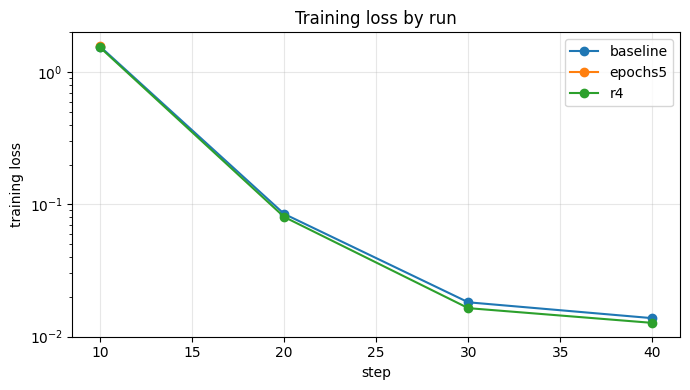

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4))
for n, r in loaded.items():
    xs, ys = zip(*r["train"]["loss_curve"]) if r["train"]["loss_curve"] else ([], [])
    ax.plot(xs, ys, marker="o", label=n)
ax.set_xlabel("step"); ax.set_ylabel("training loss"); ax.set_yscale("log"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Training loss by run"); plt.tight_layout(); plt.savefig(WORK / "loss_curves.png", dpi=150); plt.show()

In [ ]:
# 質問ごとに、どのランで落ちたかを並べる（「残った質問」は実行ごとに揺れるので、型で比べる）
per_q = {}
for n, r in loaded.items():
    rows = json.loads((WORK / f"eval_after_{n}.json").read_text(encoding="utf-8"))["rows"]
    for x in rows:
        per_q.setdefault(x["question"], {"正解 needs_review": x["gold_needs_review"]})[n] = "○" if x["both_ok"] else f"×({failure_type(x)})"
display(pd.DataFrame.from_dict(per_q, orient="index"))
for n, r in loaded.items():
    print(f"\n[{n}] 知識質問:", [(k["質問"], k["学習前の分類"], "→", k["学習後の分類"]) for k in r["knowledge"]])

,正解 needs_review,baseline,epochs5,r4
提出の期限は？,False,○,○,○
提出期限の日付と時刻を教えてください,False,○,○,○
課題の締切は何月何日の何時ですか,False,○,○,○
提出場所は？,False,○,○,○
課題の提出はどこで行いますか,False,○,○,○
提出物を出す先を教えてください,False,○,○,○
PDF 以外でも出せますか,False,○,×(根拠ありで確認に逃げた),○
提出するファイルの形式は何ですか,False,○,○,○
提出ファイルは何形式で、いくつ出しますか,False,○,○,○
相談できる時間帯は？,False,○,○,○



[baseline] 知識質問: [('この講座の最終課題の締切はいつですか', 'format_error', '→', 'asserted'), ('担当教員の名前は何ですか', 'format_error', '→', 'needs_review'), ('次回の講義のテーマは何ですか', 'format_error', '→', 'needs_review'), ('課題の提出期限はいつですか', 'format_error', '→', 'asserted')]

[epochs5] 知識質問: [('この講座の最終課題の締切はいつですか', 'format_error', '→', 'asserted'), ('担当教員の名前は何ですか', 'format_error', '→', 'needs_review'), ('次回の講義のテーマは何ですか', 'format_error', '→', 'needs_review'), ('課題の提出期限はいつですか', 'format_error', '→', 'asserted')]

[r4] 知識質問: [('この講座の最終課題の締切はいつですか', 'format_error', '→', 'asserted'), ('担当教員の名前は何ですか', 'format_error', '→', 'needs_review'), ('次回の講義のテーマは何ですか', 'format_error', '→', 'needs_review'), ('課題の提出期限はいつですか', 'format_error', '→', 'asserted')]


### 9.2 English snippet for answer.md (numbers filled in automatically)

In [ ]:
TYPE_EN = {"根拠なしに断定": "asserted on an ungrounded question", "根拠ありで確認に逃げた": "dodged a grounded question with needs-review",
           "形式の崩れ": "format broken", "語句不足": "missing required words", "": "-"}
KIND_EN = {"needs_review": "needs_review", "asserted": "asserted", "format_error": "format_error"}
changed = [", ".join(f"{k}={v}" for k, v in r["changed"].items()) for r in loaded.values() if r["changed"]]
lines = ["- Level attempted: Basic",
         "- Settings or data changed: " + ", ".join(f"`{c}`" for c in changed)
         + " (each changes exactly one value from the baseline; every run starts from a freshly loaded base model)",
         "- Results (comparison table / numbers):", "",
         "| run | change | format_rate | content_rate | final loss | train time (s) | steps | trainable % | regressions | remaining failure types |",
         "|---|---|---|---|---|---|---|---|---|---|",
         f"| before training | - | {first['before']['format_rate']:.3f} | {first['before']['content_rate']:.3f} | - | - | - | - | - | - |"]
for n, r in loaded.items():
    t = r["train"]; types = [TYPE_EN[f["type"]] for f in r["remaining_failures"]]
    tstr = "; ".join(f"{k} ×{types.count(k)}" for k in dict.fromkeys(types)) or "none"
    lines.append(f"| {n} | {', '.join(f'{k}={v}' for k, v in r['changed'].items()) or 'baseline'} | {r['after']['format_rate']:.3f} | "
                 f"{r['after']['content_rate']:.3f} | {t['final_loss']} | {t['train_seconds']} | {t['steps']} | {t['trainable_pct']} | {len(r['regressed'])} | {tstr} |")
snippet = "\n".join(lines) + "\n"
(WORK / "answer_basic.md").write_text(snippet, encoding="utf-8"); to_drive("answer_basic.md", "loss_curves.png")
print(snippet)

- Level attempted: Basic
- Settings or data changed: `num_train_epochs=5`, `lora_r=4` (each changes exactly one value from the baseline; every run starts from a freshly loaded base model)
- Results (comparison table / numbers):

| run | change | format_rate | content_rate | final loss | train time (s) | steps | trainable % | regressions | remaining failure types |
|---|---|---|---|---|---|---|---|---|---|
| before training | - | 0.095 | 0.000 | - | - | - | - | - | - |
| baseline | baseline | 1.000 | 0.905 | 0.013771359622478486 | 230.1 | 40 | 0.842 | 0 | asserted on an ungrounded question ×2 |
| epochs5 | num_train_epochs=5 | 1.000 | 0.714 | 1.5743242263793946 | 61.9 | 10 | 0.842 | 0 | dodged a grounded question with needs-review ×1; missing required words ×4; asserted on an ungrounded question ×1 |
| r4 | lora_r=4 | 1.000 | 0.905 | 0.01268608272075653 | 232.2 | 40 | 0.212 | 0 | asserted on an ungrounded question ×2 |



## 10. Homework (Advanced): train on the glossary and compare with a glossary search

**What it does**: trains on the output of `scripts/make_sft_dataset.py` (58 terms × 2 phrasings = 116 records) instead of the FAQ, and compares 4 systems on the same 45 questions with the same scoring.

| System | What it is |
| --- | --- |
| `adv_before` | base model, before training |
| `adv_after_A` | trained on the script output **as-is** (what the homework asks for) |
| `adv_after_B` | A + questions using each term's aliases + examples that answer "not in the glossary" (`RUN_AUGMENTED=True`) |
| `retrieval` | no model: finds a term name or alias in the question and returns that glossary entry |

| Question type | Example | Correct when |
| --- | --- | --- |
| `seen` (same phrasing as training) | 「LoRA」とは何ですか？ | character-bigram F1 vs. the definition ≥ 0.5 |
| `reworded` (new phrasing) | LoRAって、初心者にもわかるように言うとどういう意味？ | same |
| `alias` (alternative name) | Low-Rank Adaptationって何のことですか？ | same |
| `unknown` (not in the glossary: 8 real + 2 invented) | 「RAG（検索拡張生成）」とは何ですか？ | says it is not in the glossary |
| `reverse` (description → term) | 重みを固定し低ランク行列だけを学習する手法は？ | names the term |

F1 measures faithfulness to the glossary wording, not general correctness, so read the raw outputs as well.

**Data**: if you uploaded `glossary_sft.jsonl` (made in Codespaces with `uv run python scripts/make_sft_dataset.py > glossary_sft.jsonl`) to `/content`, it is used; otherwise the cell clones the course repo and runs the same script here.

**Can be run without section 9.** It needs sections 0–3 (tokenizer, `load_base`) and the `train_lora` function from the first cell of section 9.

In [ ]:
import shutil

def to_drive(*names):
    if not USE_DRIVE: return
    for n in names:
        if (WORK / n).exists(): shutil.copy(WORK / n, Path(CONFIG["drive_dir"]) / n)

from peft import LoraConfig  # (same train_lora as section 9; redefined so section 10 can run on its own)
from trl import SFTTrainer, SFTConfig
from datasets import Dataset

def to_chat(example):
    return {"messages": build_messages(example) + [{"role": "assistant", "content": example["target"]}]}

def train_lora(model, cfg, train_records, run_name, valid_records=None):
    """演習のセクション 4 と同じ学習。cfg の値だけを差し替えられるようにしている。学習時間と loss の推移を返す"""
    set_seed(cfg["seed"])                      # LoRA の初期値と学習順を揃える
    model.config.use_cache = False
    lora = LoraConfig(r=cfg["lora_r"], lora_alpha=cfg["lora_alpha"], lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
                      target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
    sft = SFTConfig(output_dir=str(WORK / f"ckpt_{run_name}"), num_train_epochs=cfg["num_train_epochs"],
                    per_device_train_batch_size=4, gradient_accumulation_steps=2,
                    learning_rate=cfg["lr"], lr_scheduler_type="cosine", warmup_steps=cfg["warmup_steps"],
                    logging_steps=cfg.get("logging_steps", 10), save_strategy="no",
                    fp16=False, max_length=cfg["max_seq_len"], packing=False, report_to="none", seed=cfg["seed"])
    trainer = SFTTrainer(model=model, args=sft, train_dataset=Dataset.from_list(train_records),
                         eval_dataset=Dataset.from_list(valid_records) if valid_records else None,
                         peft_config=lora, processing_class=tok)
    tuned = trainer.model
    trainable = sum(p.numel() for p in tuned.parameters() if p.requires_grad)
    total = sum(p.numel() for p in tuned.parameters())
    t0 = time.time()
    out = trainer.train()
    secs = round(time.time() - t0, 1)
    losses = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
    info = {"train_seconds": secs, "steps": trainer.state.global_step, "epochs": round(trainer.state.epoch, 2),
            "final_loss": losses[-1][1] if losses else None, "avg_train_loss": round(out.training_loss, 4),
            "loss_curve": losses, "trainable_params": trainable, "trainable_pct": round(100 * trainable / total, 3)}
    tuned.save_pretrained(WORK / f"adapter_{run_name}")
    tuned.config.use_cache = True
    tuned.eval()
    print(f"[{run_name}] 学習時間 {secs} 秒 | steps {info['steps']} | 最終 loss {info['final_loss']} | trainable {info['trainable_pct']}%")
    return tuned, info

In [ ]:
import subprocess, sys, re, random
# Advanced settings: same model and LoRA settings as CONFIG; only what the glossary data needs is changed
ADV_CFG = {**CONFIG,
    "num_train_epochs": 6,     # 116 records × 6 passes ≈ 90 steps (5–8 min on T4). More data than the FAQ (14 × 20), so fewer passes
    "max_new_tokens": 200,     # definitions are 1–3 sentences, longer than the FAQ answers (96)
    "eval_n_terms": 10,        # terms used in evaluation (3 questions each)
}
RUN_AUGMENTED = True   # False = train only variant A (script output as-is); saves ~15 min
print({k: ADV_CFG[k] for k in ["num_train_epochs", "max_new_tokens", "eval_n_terms", "lr", "lora_r"]})

{'num_train_epochs': 6, 'max_new_tokens': 200, 'eval_n_terms': 10, 'lr': 0.0002, 'lora_r': 16}


### 10.1 Training data (output of make_sft_dataset.py)

In [ ]:
# 用語集と、scripts/make_sft_dataset.py の出力（glossary_sft.jsonl）を用意する
#  - Codespaces で `uv run python scripts/make_sft_dataset.py > glossary_sft.jsonl` を実行して /content にアップロードした場合は、それを使う
#  - 無ければ講座リポジトリを clone して、同じスクリプトをここで実行する（スクリプトは標準ライブラリだけで動く）
REPO_URL = "https://github.com/matsuolab/lecture-ai-engineering-2026.git"   # 自分の fork の URL に変えてもよい
REPO = Path("/content/lecture-ai-engineering-2026")
SFT_PATH = Path("/content/glossary_sft.jsonl")
if not REPO.exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO)], check=True)
if not SFT_PATH.exists():
    out = subprocess.run([sys.executable, str(REPO / "scripts" / "make_sft_dataset.py")], capture_output=True, text=True, check=True).stdout
    SFT_PATH.write_text(out, encoding="utf-8")
    print("glossary_sft.jsonl をスクリプトで生成しました")
else:
    print("アップロード済みの glossary_sft.jsonl を使います")

sft_rows = [json.loads(l) for l in SFT_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]
GLOSSARY = json.loads((REPO / "data" / "glossary.json").read_text(encoding="utf-8"))["terms"]
TEMPLATES = ["「{term}」とは何ですか？", "{term}について簡単に説明してください。"]   # make_sft_dataset.py と同じ
print(f"用語 {len(GLOSSARY)} 語 → 学習データ {len(sft_rows)} 件（1 語 × テンプレート {len(TEMPLATES)} 種）")
print("1 件目:", json.dumps(sft_rows[0], ensure_ascii=False)[:300])
assert all(r["messages"][-1]["role"] == "assistant" for r in sft_rows)

glossary_sft.jsonl をスクリプトで生成しました
用語 58 語 → 学習データ 116 件（1 語 × テンプレート 2 種）
1 件目: {"messages": [{"role": "user", "content": "「AIエンジニアリング」とは何ですか？"}, {"role": "assistant", "content": "学習済みの基盤モデル（主にLLM）を部品として使い、実際に役立つアプリケーションやシステムを設計・構築・評価・運用する技術領域。モデルを一から作ることより、モデルの選択、データやツールとの接続、評価と改善のサイクルを回すことに重心がある。"}]}


### 10.2 Evaluation set and scoring

In [ ]:
import pandas as pd
pd.set_option("display.max_colwidth", 200)
# ===== 評価セット（自分で用意する）=====
def head(term):                       # 「LLM（大規模言語モデル）」→「LLM」
    return re.split(r"[（(]", term)[0].strip()
def names_of(t):                      # 用語の呼び名（見出し・括弧内・別名）
    ns = {t["term"], head(t["term"])} | set(t["aliases"])
    inner = re.findall(r"[（(](.+?)[）)]", t["term"])
    for x in inner: ns |= {s.strip() for s in re.split(r"[・/]", x)}
    return {n for n in ns if len(n) >= 2}
ALL_NAMES = {n.lower() for t in GLOSSARY for n in names_of(t)}

rng = random.Random(ADV_CFG["seed"])
eval_terms = rng.sample(GLOSSARY, ADV_CFG["eval_n_terms"])
REWORD = "{term}って、初心者にもわかるように言うとどういう意味？"           # 学習に無い言い回し（用語名はそのまま）
ALIAS = "{alias}って何のことですか？"                                       # 学習に無い呼び名（別名）＋学習に無い言い回し

# 用語集に無い語（実在の語 8 ＋ 架空の語 2）。正解は「用語集に無い」と答えること
UNKNOWN = ["RAG（検索拡張生成）", "埋め込みベクトル", "ベクトルデータベース", "RLHF", "DPO", "MoE（Mixture of Experts）",
           "KVキャッシュ", "知識蒸留", "スパイラル勾配正則化", "クロノ・トークナイザ"]   # 最後の 2 つは架空
for u in UNKNOWN:
    assert head(u).lower() not in ALL_NAMES and u.lower() not in ALL_NAMES, f"{u} は用語集にある"

# 逆引き（説明 → 用語名）。正解は用語名か別名を答えに含むこと
REVERSE = [
    ("基盤モデルの重みを 4bit に量子化したうえで、追加した小さな行列だけを学習する手法の名前は？", "QLoRA"),
    ("モデルの重みは固定し、低ランクの小さな行列だけを追加で学習する手法を何と呼びますか？", "LoRA"),
    ("学習データに合わせすぎて、未知のデータで性能が落ちる現象を何と言いますか？", "過学習"),
    ("LLM が事実と異なる内容をもっともらしく生成してしまう現象の名前は？", "ハルシネーション"),
    ("LLM が 1 回の呼び出しで扱える入力と出力のトークン数の上限を何と言いますか？", "コンテキストウィンドウ"),
]
BY_HEAD = {head(t["term"]): t for t in GLOSSARY}
assert all(h in BY_HEAD for _, h in REVERSE)

eval_set = []
for t in eval_terms:
    alias = max(t["aliases"], key=len)        # 一番長い別名（「r」「env」のような短すぎる別名を避ける）
    eval_set += [
        {"cat": "seen",     "question": TEMPLATES[0].format(term=t["term"]), "term": t["term"], "gold": t["definition"]},
        {"cat": "reworded", "question": REWORD.format(term=t["term"]),       "term": t["term"], "gold": t["definition"]},
        {"cat": "alias",    "question": ALIAS.format(alias=alias),           "term": t["term"], "gold": t["definition"]},
    ]
for u in UNKNOWN:
    eval_set.append({"cat": "unknown", "question": TEMPLATES[0].format(term=u), "term": u, "gold": None})
for q, h in REVERSE:
    eval_set.append({"cat": "reverse", "question": q, "term": BY_HEAD[h]["term"], "gold": BY_HEAD[h]["definition"]})
print({c: sum(e["cat"] == c for e in eval_set) for c in ["seen", "reworded", "alias", "unknown", "reverse"]}, "合計", len(eval_set))
print("評価に使う用語:", [t["term"] for t in eval_terms])

# ===== 採点 =====
PUNCT = re.compile(r"[\s、。，．,.!?！？「」『』（）()・:：;；\-]")
def bigrams(s):
    s = PUNCT.sub("", s)
    return [s[i:i+2] for i in range(len(s) - 1)]
def bigram_f1(pred, ref):
    from collections import Counter
    p, r = Counter(bigrams(pred)), Counter(bigrams(ref))
    if not p or not r: return 0.0
    ov = sum((p & r).values())
    if ov == 0: return 0.0
    prec, rec = ov / sum(p.values()), ov / sum(r.values())
    return 2 * prec * rec / (prec + rec)
REFUSAL = re.compile(r"用語集に(は)?(ありません|載っていません|記載(が|は)?ありません|含まれていません|見当たりません)|確認してください")
F1_PASS = 0.5   # 用語集の定義文との文字 bigram F1 がこれ以上なら「用語集どおりに答えた」とみなす

def score(item, answer, hit_term=None):
    """hit_term: 検索の場合に、実際に引いた見出し。逆引きは「どの項目を引いたか」で判定する（定義文に正解の語が偶然出ても正解にしない）"""
    refused = bool(REFUSAL.search(answer))
    if item["cat"] == "unknown":
        return {"ok": refused, "f1": None, "refused": refused}
    if item["cat"] == "reverse":
        t = next(x for x in GLOSSARY if x["term"] == item["term"])
        ok = (hit_term == item["term"]) if hit_term is not None or answer == NOT_FOUND_TEXT else any(n.lower() in answer.lower() for n in names_of(t))
        return {"ok": ok and not refused, "f1": round(bigram_f1(answer, item["gold"]), 3), "refused": refused}
    f1 = bigram_f1(answer, item["gold"])
    return {"ok": f1 >= F1_PASS and not refused, "f1": round(f1, 3), "refused": refused}

NOT_FOUND_TEXT = "その用語はこの講座の用語集にありません。講義資料か講師に確認してください。"
CATS = ["seen", "reworded", "alias", "unknown", "reverse"]
def summarize(label, rows):
    s = {"label": label, "n": len(rows)}
    for c in CATS:
        rs = [r for r in rows if r["cat"] == c]
        s[f"{c}_acc"] = round(sum(r["ok"] for r in rs) / len(rs), 3)
        f1s = [r["f1"] for r in rs if r["f1"] is not None]
        if f1s: s[f"{c}_f1"] = round(sum(f1s) / len(f1s), 3)
    known = [r for r in rows if r["cat"] in ("seen", "reworded", "alias")]
    s["over_refusal"] = round(sum(r["refused"] for r in known) / len(known), 3)   # 用語集にある語なのに「無い」と答えた割合
    return s

{'seen': 10, 'reworded': 10, 'alias': 10, 'unknown': 10, 'reverse': 5} 合計 45
評価に使う用語: ['Pi', 'temperature', '評価と改善のサイクル', '宿題の3レベル', 'ブランチ', 'Codespaces secret', 'devcontainer', 'ハルシネーション', 'トランスポート（stdio・Streamable HTTP）', 'システムプロンプト']


### 10.3 Baseline: glossary search (no GPU, runs instantly)

In [ ]:
# ===== 比較対象: 用語集を「検索」して定義を返す仕組み（モデルは使わない）=====
# 1) 質問文に用語名・別名がそのまま含まれていれば、一番長く一致したものを返す（英字は単語境界で判定）
# 2) 含まれていなければ「用語集にありません」と返す
# 第 1 回のエージェントのツール（用語集検索）に近い、ごく単純なキーワード検索
INDEX = []
for t in GLOSSARY:
    for n in names_of(t):
        pat = re.compile(rf"(?<![A-Za-z]){re.escape(n)}(?![A-Za-z])", re.I) if re.fullmatch(r"[\x00-\x7f]+", n) else re.compile(re.escape(n))
        INDEX.append((n, pat, t))
NOT_FOUND = NOT_FOUND_TEXT
def retrieve(question):
    hits = [(len(n), n, t) for n, pat, t in INDEX if pat.search(question)]
    if not hits: return NOT_FOUND, None
    _, n, t = max(hits, key=lambda h: h[0])
    return f"{t['term']}: {t['definition']}", t["term"]

def evaluate_retrieval(label="retrieval"):
    t0 = time.time(); rows = []
    for item in eval_set:
        ans, hit = retrieve(item["question"])
        rows.append({**item, "answer": ans, "hit_term": hit, **score(item, ans, hit)})
    s = summarize(label, rows); s["seconds"] = round(time.time() - t0, 3)
    (WORK / f"eval_{label}.json").write_text(json.dumps({"summary": s, "rows": rows}, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(s, ensure_ascii=False))
    return s, rows

In [ ]:
retr_summary, retr_rows = evaluate_retrieval()
display(pd.DataFrame(retr_rows)[["cat", "question", "hit_term", "ok", "f1"]])

{"label": "retrieval", "n": 45, "seen_acc": 1.0, "seen_f1": 0.95, "reworded_acc": 1.0, "reworded_f1": 0.95, "alias_acc": 1.0, "alias_f1": 0.95, "unknown_acc": 1.0, "reverse_acc": 0.0, "reverse_f1": 0.111, "over_refusal": 0.0, "seconds": 0.018}


,cat,question,hit_term,ok,f1
0,seen,「Pi」とは何ですか？,Pi,True,0.992
1,reworded,Piって、初心者にもわかるように言うとどういう意味？,Pi,True,0.992
2,alias,Pi coding agentって何のことですか？,Pi,True,0.992
3,seen,「temperature」とは何ですか？,temperature,True,0.916
4,reworded,temperatureって、初心者にもわかるように言うとどういう意味？,temperature,True,0.916
5,alias,温度パラメータって何のことですか？,temperature,True,0.916
6,seen,「評価と改善のサイクル」とは何ですか？,評価と改善のサイクル,True,0.960
7,reworded,評価と改善のサイクルって、初心者にもわかるように言うとどういう意味？,評価と改善のサイクル,True,0.960
8,alias,改善サイクルって何のことですか？,評価と改善のサイクル,True,0.960
9,seen,「宿題の3レベル」とは何ですか？,宿題の3レベル,True,0.957


### 10.4 Before training

In [ ]:
def gen_plain(model, question):
    # Same as the training data: no system prompt, one user turn. Same conditions before and after training
    prompt = tok.apply_chat_template([{"role": "user", "content": question}], tokenize=False, add_generation_prompt=True, enable_thinking=False)
    inputs = tok(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=ADV_CFG["max_new_tokens"], pad_token_id=tok.pad_token_id, **ADV_CFG["gen"])
    return tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def evaluate_model(model, label):
    t0 = time.time(); rows = []
    for item in eval_set:
        ans = gen_plain(model, item["question"])
        rows.append({**item, "answer": ans, **score(item, ans)})
    s = summarize(label, rows); s["seconds"] = round(time.time() - t0, 1)
    (WORK / f"eval_{label}.json").write_text(json.dumps({"summary": s, "rows": rows}, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(s, ensure_ascii=False))
    return s, rows

SIDE_EFFECT_QS = ["日本の首都はどこですか？", "1 から 10 までの和はいくつですか？", "おはようございます。今日の気分はどうですか？"]
def side_effects(model):
    return [{"質問": q, "出力": gen_plain(model, q)} for q in SIDE_EFFECT_QS]

In [ ]:
# Free the exercise models (sections 3-8) so the next runs have the whole GPU
for _name in ["trainer", "tuned", "model", "model_4bit"]:
    if _name in globals(): del globals()[_name]
cleanup()
print("GPU memory in use (GB):", round(torch.cuda.memory_allocated() / 1e9, 2) if torch.cuda.is_available() else "-")

m = load_base()
before_summary_adv, before_rows_adv = evaluate_model(m, "adv_before")
before_side = side_effects(m)
del m; cleanup()

GPU memory in use (GB): 3.05


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

{"label": "adv_before", "n": 45, "seen_acc": 0.0, "seen_f1": 0.075, "reworded_acc": 0.0, "reworded_f1": 0.06, "alias_acc": 0.0, "alias_f1": 0.089, "unknown_acc": 0.0, "reverse_acc": 0.2, "reverse_f1": 0.14, "over_refusal": 0.0, "seconds": 458.7}


### 10.5 (A) Train on the script output as-is → evaluate

In [ ]:
m = load_base()
tuned_A, info_A = train_lora(m, ADV_CFG, sft_rows, "glossary_A")
A_summary, A_rows = evaluate_model(tuned_A, "adv_after_A")
A_side = side_effects(tuned_A)
del tuned_A, m; cleanup()

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Tokenizing train dataset:   0%|          | 0/116 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/116 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/116 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/116 [00:00<?, ? examples/s]

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 248046}.


Step,Training Loss
10,3.269008
20,2.209309
30,1.676813
40,1.017926
50,0.613418
60,0.422407
70,0.241416
80,0.226330
90,0.170593


[glossary_A] 学習時間 216.5 秒 | steps 90 | 最終 loss 0.17059319019317626 | trainable 0.842%
{"label": "adv_after_A", "n": 45, "seen_acc": 0.9, "seen_f1": 0.883, "reworded_acc": 0.6, "reworded_f1": 0.573, "alias_acc": 0.2, "alias_f1": 0.291, "unknown_acc": 0.0, "reverse_acc": 0.0, "reverse_f1": 0.206, "over_refusal": 0.0, "seconds": 157.6}


### 10.6 (B) Augmented data → train → evaluate (optional)

In [ ]:
# ===== (B) 拡張データ: スクリプトの出力 ＋ 別名での質問 ＋ 「用語集に無い」と答える例 =====
# スクリプトの docstring にある工夫（言い回しを増やす・別名でも質問を作る）を試す版。A との差で「データ設計の効き目」を見る
TRAIN_UNKNOWN = ["ビームサーチ", "アテンション機構", "トランスフォーマー", "強化学習", "ベイズ最適化", "勾配ブースティング", "ドロップアウト", "バッチ正規化"]
for u in TRAIN_UNKNOWN:
    assert u.lower() not in ALL_NAMES and u not in UNKNOWN
REFUSE_ANSWER = "その用語はこの講座の用語集にありません。講義資料か講師に確認してください。"
aug_rows = list(sft_rows)
for t in GLOSSARY:
    for a in t["aliases"]:
        if len(a) >= 2:
            aug_rows.append({"messages": [{"role": "user", "content": TEMPLATES[0].format(term=a)}, {"role": "assistant", "content": t["definition"]}]})
for u in TRAIN_UNKNOWN:
    for tpl in TEMPLATES:
        aug_rows.append({"messages": [{"role": "user", "content": tpl.format(term=u)}, {"role": "assistant", "content": REFUSE_ANSWER}]})
# 評価の質問が学習データにそのまま入っていないことを確認（seen は意図的に同じ文）
train_qs_aug = {r["messages"][0]["content"] for r in aug_rows}
leak = [e["question"] for e in eval_set if e["cat"] != "seen" and e["question"] in train_qs_aug]
assert not leak, leak
print(f"(A) {len(sft_rows)} 件 → (B) {len(aug_rows)} 件（別名 +{len(aug_rows) - len(sft_rows) - 2 * len(TRAIN_UNKNOWN)}、用語集に無い例 +{2 * len(TRAIN_UNKNOWN)}）")

(A) 116 件 → (B) 243 件（別名 +111、用語集に無い例 +16）


In [ ]:
B_summary, B_rows, info_B, B_side = None, None, None, None
if RUN_AUGMENTED:
    m = load_base()
    tuned_B, info_B = train_lora(m, ADV_CFG, aug_rows, "glossary_B")
    B_summary, B_rows = evaluate_model(tuned_B, "adv_after_B")
    B_side = side_effects(tuned_B)
    del tuned_B, m; cleanup()

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Tokenizing train dataset:   0%|          | 0/243 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/243 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/243 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/243 [00:00<?, ? examples/s]

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 248046}.


Step,Training Loss
10,3.268950
20,2.160530
30,1.841836
40,1.074072
50,0.797883
60,0.572581
70,0.344857
80,0.249446
90,0.221607
100,0.163873


[glossary_B] 学習時間 444.8 秒 | steps 186 | 最終 loss 0.11509394645690918 | trainable 0.842%
{"label": "adv_after_B", "n": 45, "seen_acc": 1.0, "seen_f1": 1.0, "reworded_acc": 0.9, "reworded_f1": 0.905, "alias_acc": 1.0, "alias_f1": 1.0, "unknown_acc": 0.2, "reverse_acc": 0.0, "reverse_f1": 0.25, "over_refusal": 0.0, "seconds": 152.2}


### 10.7 Compare

In [ ]:
summaries = [before_summary_adv, A_summary] + ([B_summary] if B_summary else []) + [retr_summary]
cols = ["label"] + [f"{c}_acc" for c in CATS] + ["over_refusal", "seen_f1", "reworded_f1", "alias_f1", "seconds"]
cmp_df = pd.DataFrame(summaries)[cols].set_index("label")
display(cmp_df)

# 質問ごとの出力（○×と原文）
systems = {"before": before_rows_adv, "adv_after_A": A_rows, **({"adv_after_B": B_rows} if B_rows else {}), "retrieval": retr_rows}
detail = []
for i, item in enumerate(eval_set):
    d = {"cat": item["cat"], "question": item["question"]}
    for name, rows in systems.items():
        d[name] = ("○ " if rows[i]["ok"] else "× ") + rows[i]["answer"][:120].replace("\n", " ")
    detail.append(d)
display(pd.DataFrame(detail))
print("副作用チェック（用語集と無関係の質問）")
display(pd.DataFrame([{"質問": b["質問"], "before": b["出力"][:100], "adv_after_A": a["出力"][:100], **({"adv_after_B": c["出力"][:100]} if B_side else {})}
                      for b, a, c in zip(before_side, A_side, B_side or A_side)]))

,seen_acc,reworded_acc,alias_acc,unknown_acc,reverse_acc,over_refusal,seen_f1,reworded_f1,alias_f1,seconds
label,,,,,,,,,,
adv_before,0.0,0.0,0.0,0.0,0.2,0.0,0.075,0.060,0.089,458.700
adv_after_A,0.9,0.6,0.2,0.0,0.0,0.0,0.883,0.573,0.291,157.600
adv_after_B,1.0,0.9,1.0,0.2,0.0,0.0,1.000,0.905,1.000,152.200
retrieval,1.0,1.0,1.0,1.0,0.0,0.0,0.950,0.950,0.950,0.018


,cat,question,before,adv_after_A,adv_after_B,retrieval
0,seen,「Pi」とは何ですか？,× 「Pi」とは、**円周率**（π）を指します。 これは、円が中心に点状に点印を印をつけて描いたとき、その円の周長と半径の比を表す数値です。 * **定義**: $\pi = \frac{2 \pi}{3}$ * **値**: 約,○ ターミナルで動くオープンソース（MITライセンス）のコーディングエージェント。最小限の機能とシステムプロンプトで構成し、利用者が拡張して使う設計。2026年10月に1.0が公開された。npmのパッケージ名は @earendil-works/,○ ターミナルで動くオープンソース（MITライセンス）のコーディングエージェント。最小限の機能とシステムプロンプトで構成し、利用者が拡張して使う設計。2026年10月に1.0が公開された。npmのパッケージ名は @earendil-works/,○ Pi: ターミナルで動くオープンソース（MITライセンス）のコーディングエージェント。最小限の機能とシステムプロンプトで構成し、利用者が拡張して使う設計。2026年10月に1.0が公開された。npmのパッケージ名は @earendil-wo
1,reworded,Piって、初心者にもわかるように言うとどういう意味？,× 「ピ」は、数学やプログラミングの分野で非常に重要な概念です。初心者でも理解できるように、**「ピ」は「点（ポイント）」**という意味です。 具体的には、以下の 3 つの点のいずれか、またはその間の距離を指します。 ### 1. 数学の「,× MCPのサーバーとして使う、かつツール（コマンド）の数えろと設計した小さなプログラム。Piは0.2.0で1.0への重大な変更がないため、今すぐ使える。本講座の第2回演習で、設定したMCPサーバーとしてPiを起動し、公開したMCPコモンキャス,○ ターミナルで動くオープンソース（MITライセンス）のコーディングエージェント。最小限の機能とシステムプロンプトで構成し、利用者が拡張して使う設計。2026年10月に1.0が公開された。npmのパッケージ名は @earendil-works/,○ Pi: ターミナルで動くオープンソース（MITライセンス）のコーディングエージェント。最小限の機能とシステムプロンプトで構成し、利用者が拡張して使う設計。2026年10月に1.0が公開された。npmのパッケージ名は @earendil-wo
2,alias,Pi coding agentって何のことですか？,× **Pi coding agent**（パイコードエージェント）は、主に **Python** の言語を使って、特定の目的（例：自動テスト、データ処理、自動化）に最適化された、**AI と機械学習を組み合わせたソフトウェア**です。 簡単,× Claude CodeのPi版。Piのプログラミングエンジン（Pi-3）をコードエディタとして取り込む、とけがれたツールやコマンドを自動で検索・補完・実行する、という整套eutopiaのプログラミングエージェント。Claude Deskto,○ ターミナルで動くオープンソース（MITライセンス）のコーディングエージェント。最小限の機能とシステムプロンプトで構成し、利用者が拡張して使う設計。2026年10月に1.0が公開された。npmのパッケージ名は @earendil-works/,○ Pi: ターミナルで動くオープンソース（MITライセンス）のコーディングエージェント。最小限の機能とシステムプロンプトで構成し、利用者が拡張して使う設計。2026年10月に1.0が公開された。npmのパッケージ名は @earendil-wo
3,seen,「temperature」とは何ですか？,× 「temperature」は、**温度**（熱の強さや状態）を意味します。 この言葉は英語の「temperature」の直訳で、主に以下の意味で使われます： * **物理的・化学的状態**: 物質の分子の運動や熱エネルギーの分布を表,○ 次のトークンを選ぶときのランダムさを調整する設定値。低いほど出力が安定し、高いほど多様になる。同じ質問でも回答が変わる理由の一つ。,○ 次のトークンを選ぶときのランダムさを調整する設定値。低いほど出力が安定し、高いほど多様になる。同じ質問でも回答が変わる理由の一つ。,○ temperature: 次のトークンを選ぶときのランダムさを調整する設定値。低いほど出力が安定し、高いほど多様になる。同じ質問でも回答が変わる理由の一つ。
4,reworded,temperatureって、初心者にもわかるように言うとどういう意味？,× 「温度」は、**「熱さ（熱い）」**という感覚を指す言葉です。 初心者でも理解しやすいように、この言葉は以下の 3 つの視点から説明できます。 ### 1. 温度が高いと「熱い」 最も直感的なイメージです。 * **例**: 水が沸,○ 次のトークンを選ぶときのランダムさを調整する設定値。低いほど出力が安定し、高いほど多様になる。同じ質問でも回答が変わる理由の一つ。,○ 次のトークンを選ぶときのランダムさを調整する設定値。低いほど出力が安定し、高いほど多様になる。同じ質問でも回答が変わる理由の一つ。,○ temperature: 次のトークンを選ぶときのランダムさを調整する設定値。低いほど出力が安定し、高いほど多様になる。同じ質問でも回答が変わる理由の一つ。
5,alias,温度パラメータって何のことですか？,× **温度パラメータ**とは、物理学や工学において、**温度**という物理量を記述するパラメータのことです。 具体的には、以下の 2 つの側面から考えられます。 ### 1. 物理的な定義 温度は、物質の分子の平均運動エネルギーを表す重要,× 学習データにわたるvariabelを均等に扱うための調整値。大きいほど学習する範囲が広くなり、小さいほどは学習する範囲が狭くなる。,○ 次のトークンを選ぶときのランダムさを調整する設定値。低いほど出力が安定し、高いほど多様になる。同じ質問でも回答が変わる理由の一つ。,○ temperature: 次のトークンを選ぶときのランダムさを調整する設定値。低いほど出力が安定し、高いほど多様になる。同じ質問でも回答が変わる理由の一つ。
6,seen,「評価と改善のサイクル」とは何ですか？,× 「評価と改善のサイクル」とは、組織や個人が**成果を測り、それを基に改善策を策定し、継続的に向上させるプロセス**を指します。 このサイクルは、単なる「評価」ではなく、**「評価 → 改善 → 再評価」**という一連の連続的な行動を意味し,○ 作る→測る→直すを繰り返す開発の進め方。AIアプリは出力が確率的に揺れるため、感覚ではなく評価データや指標で良し悪しを判断し、その結果をもとにプロンプト・データ・モデル・ツールを改善する。本講座では学習支援エージェントを題材に、回をまたいで,○ 作る→測る→直すを繰り返す開発の進め方。AIアプリは出力が確率的に揺れるため、感覚ではなく評価データや指標で良し悪しを判断し、その結果をもとにプロンプト・データ・モデル・ツールを改善する。本講座では学習支援エージェントを題材に、回をまたいで,○ 評価と改善のサイクル: 作る→測る→直すを繰り返す開発の進め方。AIアプリは出力が確率的に揺れるため、感覚ではなく評価データや指標で良し悪しを判断し、その結果をもとにプロンプト・データ・モデル・ツールを改善する。本講座では学習支援エージェン
7,reworded,評価と改善のサイクルって、初心者にもわかるように言うとどういう意味？,× 「評価と改善のサイクル」は、**「自分自身を振り返り、次にどうすればいいか、そしてそれを繰り返すプロセス」**を指します。 初心者でも理解しやすいように、**「自分の成長の道筋」**というイメージで説明します。 ### 1. 基本のイメ,× 作ったものを使うか、使うものを次の回へ返すか、を考えながら進める開発の進め方。本講座では質問応答で終わるため、使う→使う→使うの方向へ進める。結果が良くないときは改善する。,○ 作る→測る→直すを繰り返す開発の進め方。AIアプリは出力が確率的に揺れるため、感覚ではなく評価データや指標で良し悪しを判断し、その結果をもとにプロンプト・データ・モデル・ツールを改善する。本講座では学習支援エージェントを題材に、回をまたいで,○ 評価と改善のサイクル: 作る→測る→直すを繰り返す開発の進め方。AIアプリは出力が確率的に揺れるため、感覚ではなく評価データや指標で良し悪しを判断し、その結果をもとにプロンプト・データ・モデル・ツールを改善する。本講座では学習支援エージェン
8,alias,改善サイクルって何のことですか？,× **改善サイクル**（Improvement Cycle）とは、企業や組織において、**「現状を改善し、その改善を継続して維持するプロセス」**を指します。 単に「改善」だけでなく、その改善が**「継続的に効果的」と「持続可能な状態」**,× 学習→表現→評価→改善を繰り返すAIアプリの進め方。回数を数えるMCPサーバーの呼び出し数や、AIE scoreの平均がサイクルの長さ。,○ 作る→測る→直すを繰り返す開発の進め方。AIアプリは出力が確率的に揺れる

副作用チェック（用語集と無関係の質問）


,質問,before,adv_after_A,adv_after_B
0,日本の首都はどこですか？,日本の首都は**東京**です。\n\n東京は日本最大の都市であり、日本経済の中心地、政治・行政の中心地、そして文化の中心地となっています。また、東京は世界で最も人口が多い都市の一つであり、世界最大の都市圏,東京。2026年10月、法案で都名から「東京都」と読み替えた。本講座では、本講座の地域は東京都区部と考える。,東京。第3回の首都連盟の演習で、模擬の首都に使う。実体の首都は日本国は東京、自国は東京。
1,1 から 10 までの和はいくつですか？,1 から 10 までの整数の和は、**55** です。\n\n計算方法は以下の通りです：\n* 1 の和：1\n* 2 の和：1 + 2 = 3\n* 3 の和：1 + 2 + 3 = 6\n*,10 の桁数（最大10桁）なので、10^10 の値に達し、メモリはかかりません。,9
2,おはようございます。今日の気分はどうですか？,おはようございます！元気ですね。\n\n今日はどうでしたか？何か特別なことがあったのか、また何か新しい発見があるのか、教えてくださいね。,学習済みの知識で自由に作業できる状態。本講座では作業の進め方や成果の表示、宿題の提出などを実際に体験する。休みの日は知識を振り返るだけなので、作業の進め方が変わる。,AIE2026の演習と宿題の進捗を簡単に伝えられるツール。無料の枠は限られるので、使うたびに枠を新しく選ぶ。


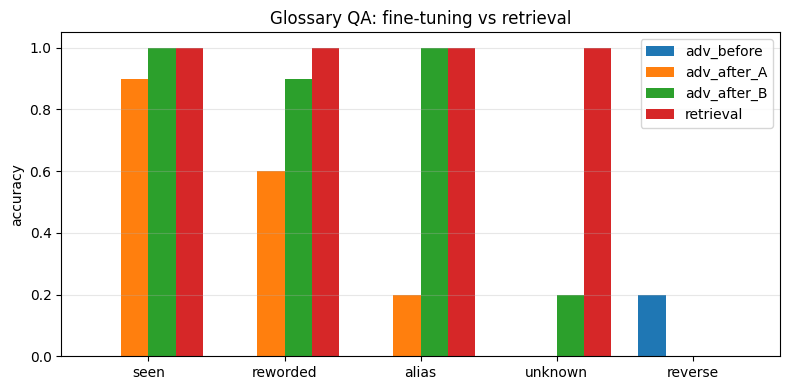

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(CATS)); w = 0.8 / len(summaries)
for i, s in enumerate(summaries):
    ax.bar([j + i * w for j in x], [s[f"{c}_acc"] for c in CATS], width=w, label=s["label"])
ax.set_xticks([j + w * (len(summaries) - 1) / 2 for j in x]); ax.set_xticklabels(CATS)
ax.set_ylim(0, 1.05); ax.set_ylabel("accuracy"); ax.legend(); ax.grid(axis="y", alpha=.3)
ax.set_title("Glossary QA: fine-tuning vs retrieval"); plt.tight_layout(); plt.savefig(WORK / "adv_compare.png", dpi=150); plt.show()

### 10.8 result_advanced.json and English snippet for answer.md

In [ ]:
result = {
    "config": {k: v for k, v in CONFIG.items() if k not in ("work_dir", "drive_dir")},
    "versions": {m.__name__: m.__version__ for m in [transformers, peft, trl, torch]},
    "method": "LoRA（量子化なし）", "data": {"A": "make_sft_dataset.py の出力そのまま", "B": "A + 別名 + 用語集に無い例" if RUN_AUGMENTED else None},
    "eval_terms": [t["term"] for t in eval_terms], "unknown_terms": UNKNOWN,
    "train": {"A": info_A, "B": info_B}, "summaries": summaries,
    "side_effects": {"before": before_side, "adv_after_A": A_side, "adv_after_B": B_side},
    "executed_training_myself": True,
}
(WORK / "result_advanced.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")

hdr = "| system | seen | reworded | alias | unknown (said not in glossary) | reverse | over-refusal | seen F1 | train time (s) |\n|---|---|---|---|---|---|---|---|---|"
def line(s, secs):
    return f"| {s['label']} | {s['seen_acc']:.2f} | {s['reworded_acc']:.2f} | {s['alias_acc']:.2f} | {s['unknown_acc']:.2f} | {s['reverse_acc']:.2f} | {s['over_refusal']:.2f} | {s.get('seen_f1', 0):.2f} | {secs} |"
tbl = "\n".join([hdr, line(before_summary_adv, "-"), line(A_summary, info_A["train_seconds"])]
                + ([line(B_summary, info_B["train_seconds"])] if B_summary else []) + [line(retr_summary, "0 (no training)")])
b_txt = f" For comparison, also trained (B) on {len(aug_rows)} records: A + questions using each term's aliases + examples that answer \"not in the glossary\"." if RUN_AUGMENTED else ""
snippet = f"""- Level attempted: Advanced
- Settings or data changed: trained (A) on the output of `scripts/make_sft_dataset.py` ({len(sft_rows)} records).{b_txt} {ADV_CFG['num_train_epochs']} epochs, max_new_tokens {ADV_CFG['max_new_tokens']}, everything else as in the exercise. Evaluation: {ADV_CFG['eval_n_terms']} terms × 3 question types (seen / reworded / alias) + {len(UNKNOWN)} terms not in the glossary + {len(REVERSE)} reverse-lookup questions = {len(eval_set)} questions. A glossary answer is correct when its character-bigram F1 against the glossary definition is ≥ {F1_PASS}; an unknown term is correct when the answer says it is not in the glossary; a reverse question is correct when the answer names the term
- Results (comparison table / numbers):

{tbl}

  - Final loss: A {info_A['final_loss']}{', B ' + str(info_B['final_loss']) if info_B else ''}
"""
(WORK / "answer_advanced.md").write_text(snippet, encoding="utf-8")
to_drive("result_advanced.json", "answer_advanced.md", "adv_compare.png", "eval_adv_before.json", "eval_adv_after_A.json", "eval_adv_after_B.json", "eval_retrieval.json")
print(snippet)

- Level attempted: Advanced
- Settings or data changed: trained (A) on the output of `scripts/make_sft_dataset.py` (116 records). For comparison, also trained (B) on 243 records: A + questions using each term's aliases + examples that answer "not in the glossary". 6 epochs, max_new_tokens 200, everything else as in the exercise. Evaluation: 10 terms × 3 question types (seen / reworded / alias) + 10 terms not in the glossary + 5 reverse-lookup questions = 45 questions. A glossary answer is correct when its character-bigram F1 against the glossary definition is ≥ 0.5; an unknown term is correct when the answer says it is not in the glossary; a reverse question is correct when the answer names the term
- Results (comparison table / numbers):

| system | seen | reworded | alias | unknown (said not in glossary) | reverse | over-refusal | seen F1 | train time (s) |
|---|---|---|---|---|---|---|---|---|
| adv_before | 0.00 | 0.00 | 0.00 | 0.00 | 0.20 | 0.00 | 0.07 | - |
| adv_after_A | 0.90 |